![Banner](../../../../Images/Banner/03_spatial_analysis/03_08_banner_spatial_analysis_capstone.png)


# Flood Susceptibility Mapping in the Sylhet Haor Basin, Bangladesh


This is Capstone 1 of the spatial analysis module (Part 7). Earlier notebooks teach one method at a time. This one starts from a planning question for the haor basin of north-east Bangladesh and builds a flood susceptibility map from a radar inventory, terrain and soil factors, and three model families.

**Data:** Sentinel-1 flood extent, national terrain and soil layers, NDVI, water-table depth, the river network, population and dekadal rainfall in `data/Sylhet_flood_susceptibility_mapping`.

**Study area:** Sunamganj and Netrakona haors, 1,962 km² at 250 m.

**Library:** `geolattice.spatial_analysis`

## Overview

The **haor basin** of north-east Bangladesh is a bowl of wetlands, rice fields and villages between the Meghalaya hills of India to the north and the Meghna river system to the south. It floods every year. In the dry season (December to April) the haor beds are drained and planted with *boro* rice; from May onward, rain over the hills and over the basin fills them again. When intense pre-monsoon or monsoon rain comes early, the water arrives before the harvest, as a **flash flood**, and both crops and homesteads are lost.

A **flood susceptibility map** answers one question: *where is water most likely to stand when a large flood occurs, given the terrain, soils and land?* It does not say when or how deep, so it is a planning tool for embankments, shelters and crop calendars, not a forecast.

This capstone builds that map for a 1,962 km² window over the **Sunamganj and Netrakona haors** at **250 m** resolution, using

- a Sentinel-1 radar flood map from the 2025 monsoon as the **flood inventory** (training and test data);
- national 250 m layers of elevation, land type, soil drainage, permeability and texture, 1 km NDVI and water-table depth for 2020, the LGED river network and a 2020 population grid;
- dekadal rainfall by district (a CHIRPS-based subnational table) to put the 2025 event in context.

Three families of model are built and compared, following Module 03: a **bivariate statistical** model (frequency ratio), a **knowledge-driven multi-criteria** model (AHP-weighted fuzzy overlay) and **machine learning** (logistic regression, random forest, gradient boosting).

## Overview

| Stage | Question | Main tools |
|---|---|---|
| **Analysis grid** | How do layers in four projections and three cell sizes become one stack? | `AnalysisGrid`, `warp_to_grid` |
| **Flood inventory** | Where was water at the 2025 flood peak? | Sentinel-1 VH backscatter, Otsu threshold, `block_fraction` |
| **Rainfall context** | How unusual was the rain that caused it? | dekadal CHIRPS by district |
| **Conditioning factors** | What describes each 250 m cell? | `fill_depressions`, `d8_pointer`, `d8_flow_accumulation`, `extract_streams`, `elevation_above_stream`, `slope`, `tpi`, `twi` |
| **Factor screening** | Which factors separate flooded from dry cells, and which are redundant? | single-factor AUC, correlation, VIF, frequency ratio |
| **Model 1: frequency ratio** | How much more often is each factor class flooded? | frequency ratio, flood susceptibility index |
| **Model 2: multi-criteria** | Where do expert rules place high susceptibility? | AHP weights, `small`, `large`, `linear`, `weighted_linear_combination` |
| **Model 3: machine learning** | What do the observations themselves say? | logistic regression, random forest, gradient boosting; spatial cross-validation |
| **Validation** | Which model ranks unseen flooded cells highest? | ROC, success- and prediction-rate curves, an independent radar date |
| **Uncertainty** | How stable are the maps? | `monte_carlo_weights`, label-threshold test, `jaccard_index` |
| **Exposure** | How many people live on highly susceptible land, and where? | population grid, upazila boundaries |

### What this notebook reuses

| Topic | Notebook |
|---|---|
| DEM conditioning and flow routing | [`03_02_03_hydrology_modeling.ipynb`](../03_02_digital_terrain_modeling/03_02_03_hydrology_modeling.ipynb) |
| Terrain derivatives | [`03_02_02_terrain_analysis.ipynb`](../03_02_digital_terrain_modeling/03_02_02_terrain_analysis.ipynb) |
| Fuzzy membership and weighted overlay | [`03_04_02_00_fuzzy_logic_foundations.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_02_00_fuzzy_logic_foundations.ipynb), [`03_04_01_03_weighted_suitability.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_01_03_weighted_suitability.ipynb) |
| Weight uncertainty | [`03_04_03_sensitivity_uncertainty.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_03_sensitivity_uncertainty.ipynb) |
| The same three model families on a landslide inventory | [`03_08_04_landslide_susceptibility.ipynb`](03_08_04_landslide_susceptibility.ipynb) |

## Table of Contents

1. [Setup](#setup)
2. [Problem statement and study area](#problem-statement-and-study-area)
3. [One analysis grid](#one-analysis-grid)
4. [The flood inventory from Sentinel-1](#the-flood-inventory-from-sentinel-1)
5. [Rainfall context](#rainfall-context)
6. [Conditioning factors](#conditioning-factors)
7. [Factor screening](#factor-screening)
8. [Model 1: frequency ratio](#model-1-frequency-ratio)
9. [Model 2: AHP multi-criteria model](#model-2-ahp-multi-criteria-model)
10. [Model 3: machine learning](#model-3-machine-learning)
11. [What drives susceptibility?](#what-drives-susceptibility)
12. [Validation of all models](#validation-of-all-models)
13. [Susceptibility classes and model agreement](#susceptibility-classes-and-model-agreement)
14. [Uncertainty](#uncertainty)
15. [Exposure](#exposure)
16. [Outputs](#outputs)
17. [Limitations](#limitations)
18. [Where to go next](#where-to-go-next)

## Setup

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports.
import sys  # make the capstone helper module importable
import time  # report how long the heavier steps take
import warnings  # silence harmless warnings
from pathlib import Path  # filesystem paths

# Third-party numeric / geospatial / plotting stack.
import geopandas as gpd  # AOI, rivers, upazilas
import matplotlib.pyplot as plt  # maps and charts
import numpy as np  # arrays
import pandas as pd  # tables
from IPython.display import display  # rich table previews
from matplotlib.colors import BoundaryNorm, ListedColormap  # class maps
from scipy import ndimage  # moving windows and distances

# Machine learning (scikit-learn).
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Shared capstone helpers live next to this notebook.
sys.path.insert(0, str(Path.cwd()))
import data_processing as dp  # paths, analysis grid, warping helpers

import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    ROOT = dp.find_repo_root()

# GeoLattice tools.
from geolattice.spatial_analysis import (
    d8_flow_accumulation,  # contributing area in cells
    d8_pointer,  # D8 flow direction
    elevation_above_stream,  # height above nearest drainage (HAND)
    extract_streams,  # threshold the accumulation into a network
    fill_depressions,  # priority-flood depression filling
    jaccard_index,  # overlap of two top-class masks
    large,  # sigmoid membership, large values -> 1
    linear,  # linear ramp membership
    monte_carlo_weights,  # Dirichlet weight uncertainty
    slope,  # slope gradient
    small,  # sigmoid membership, small values -> 1
    tpi,  # topographic position index
    weighted_linear_combination,  # weighted linear combination
)
from geolattice.spatial_analysis import surface_hydrology  # D-infinity TWI
from geolattice.viz import apply_map_style

apply_map_style()
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
RNG = np.random.default_rng(2025)  # one seed for every random step

SRC = ROOT / "Data" / "03_spatial_analysis" / "Sylhet_flood_susceptibility_mapping"
BD = SRC / "Bangladesh"  # national rasters, rivers, rainfall
S1 = SRC / "Sylhet_sentinel1"  # AOI and Sentinel-1 products
UPAZILA = ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "Shapefiles" / "bd_upzila_GCS.shp"
OUT = dp.capstone_dir(ROOT, "sylhet_flood")
print(f"Inputs:  {SRC}")
print(f"Outputs: {OUT}")

Inputs:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/Sylhet_flood_susceptibility_mapping
Outputs: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/capstone_spatial_analysis/sylhet_flood


## Problem statement and study area

**Study area.** The rectangle in `sylhet_aoi.geojson` (90.91 to 91.38 °E, 24.81 to 25.19 °N) covers most of Sunamganj district (Sylhet division) and the north-east of Netrakona district (Mymensingh division). It contains some of the largest haors of the country, among them Tanguar, Shanir and Matian, and the Baulai and Kangsha rivers that drain them toward the Meghna. Most of the land lies between 3 and 15 m above sea level; the northern edge touches the foot of the Meghalaya plateau, which receives some of the highest rainfall on Earth.

**The 2025 season.** Heavy rain in mid and late May 2025 over Meghalaya and the basin brought water down the hill streams into the haors, and the basin stayed wet through the monsoon. Four Sentinel-1 scenes in this folder (24 May, 5 June, 11 July and 16 August 2025) record it.

**Question.** Which parts of the basin are most susceptible to flooding, which conditions explain the pattern, and how many people live on the most susceptible land in each upazila?

In [2]:
aoi = gpd.read_file(S1 / "sylhet_aoi.geojson").to_crs("EPSG:32646")  # WGS 84 / UTM 46N
GRID = dp.AnalysisGrid.around(aoi.total_bounds, 250.0, "EPSG:32646")
print(f"AOI area: {aoi.area.sum() / 1e6:,.0f} km²")
print(f"Analysis grid: {GRID.shape[0]} rows x {GRID.shape[1]} columns of {GRID.res:.0f} m, {GRID.crs}")

# Upazilas (sub-districts) that intersect the AOI, clipped to it.
upz = gpd.read_file(UPAZILA, bbox=tuple(gpd.read_file(S1 / "sylhet_aoi.geojson").total_bounds))
upz = upz.to_crs(GRID.crs).clip(aoi)
upz = upz[upz.area > 1e6][["ADM3_EN", "ADM3_PCODE", "ADM2_EN", "ADM2_PCODE", "geometry"]].reset_index(drop=True)
display(upz.assign(area_km2=upz.area / 1e6).drop(columns="geometry"))

AOI area: 1,962 km²
Analysis grid: 172 rows x 191 columns of 250 m, EPSG:32646


,ADM3_EN,ADM3_PCODE,ADM2_EN,ADM2_PCODE,area_km2
0,Khaliajuri,BD457238,Netrakona,BD4572,5.236
1,Atpara,BD457204,Netrakona,BD4572,9.549
2,Mohanganj,BD457263,Netrakona,BD4572,148.652
3,Barhatta,BD457209,Netrakona,BD4572,75.131
4,Dharampasha,BD609032,Sunamganj,BD6090,501.170
5,Kalmakanda,BD457240,Netrakona,BD4572,72.265
6,Derai,BD609029,Sunamganj,BD6090,115.200
7,Dakshin Sunamganj,BD609027,Sunamganj,BD6090,93.486
8,Jamalganj,BD609050,Sunamganj,BD6090,326.916
9,Sunamganj Sadar,BD609089,Sunamganj,BD6090,101.019


## One analysis grid

The inputs come in four coordinate systems and three cell sizes:

| Layers | Native grid | CRS |
|---|---|---|
| Sentinel-1 backscatter and flood map | 30 m | WGS 84 / UTM 46N |
| DEM, land type, soil drainage, permeability, texture, slope class, depth class, soil type, AEZ | 250 m | transverse Mercator on WGS 84, central meridian 90 °E |
| NDVI and water table (16-day, 2020) | about 1 km | the same transverse Mercator, but the CRS tag is missing from the files |
| Land use 2020 | 0.01° | geographic WGS 84 |
| Population 2020 | about 1 km | the same transverse Mercator |

All are warped to one **250 m UTM 46N grid** aligned to multiples of 250 m, the native cell size of the DEM and soil maps. Classes use nearest neighbour, continuous layers bilinear interpolation. The NDVI and water-table files carry the same grid origin as the DEM, so the DEM's CRS is assigned to them before warping.

The **study mask** keeps cells inside the AOI rectangle that have a DEM value; cells north of the border, in India, have none.

Study cells: 30,826 (1,927 km²); outside Bangladesh or AOI: 2,026
DEM in study area: -22.1 to 35.3 m, median 7.9 m; 12 cells below 0 m


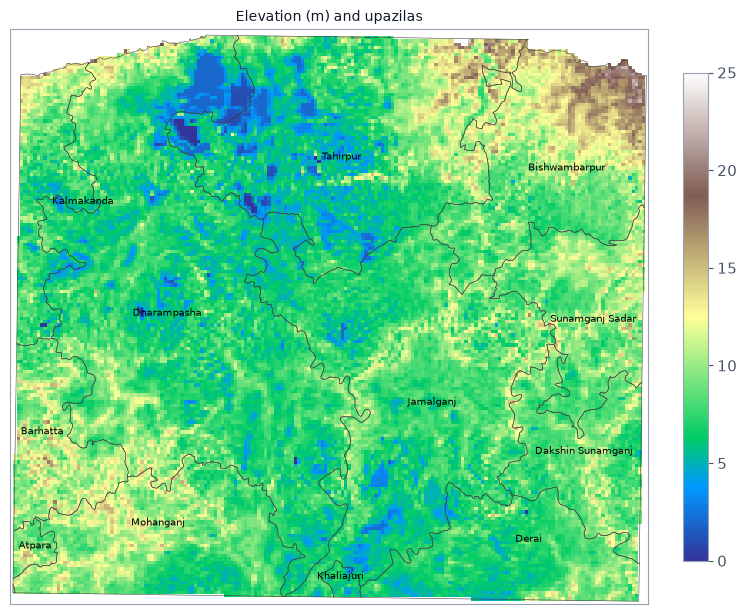

In [3]:
from osgeo import gdal  # only to read the CRS definition of the national rasters

TM_WKT = gdal.Open(str(BD / "DEM.tif")).GetProjection()  # CRS of the national 250 m rasters


def to_grid(path, resample="near", src_srs=None):
    """Warp one raster onto the analysis grid."""
    return dp.warp_to_grid(path, GRID, resample=resample, src_srs=src_srs)


dem_raw = to_grid(BD / "DEM.tif", "bilinear")
in_aoi = dp.rasterize_geometries(aoi.geometry, GRID, all_touched=False).astype(bool)
STUDY = in_aoi & np.isfinite(dem_raw)
print(f"Study cells: {STUDY.sum():,} ({STUDY.sum() * 0.0625:,.0f} km²); "
      f"outside Bangladesh or AOI: {(~STUDY).sum():,}")
print(f"DEM in study area: {np.nanmin(dem_raw[STUDY]):.1f} to {np.nanmax(dem_raw[STUDY]):.1f} m, "
      f"median {np.nanmedian(dem_raw[STUDY]):.1f} m; {np.sum(dem_raw[STUDY] < 0)} cells below 0 m")


def show(ax, arr, title, cmap="viridis", vmin=None, vmax=None, mask=True, **kw):
    """Map one grid with the upazila outlines."""
    a = np.where(STUDY, arr, np.nan) if mask else arr
    im = ax.imshow(a, extent=GRID.extent, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest", **kw)
    upz.boundary.plot(ax=ax, color="0.25", linewidth=0.4)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


fig, ax = plt.subplots(figsize=(9, 8))
im = show(ax, dem_raw, "Elevation (m) and upazilas", "terrain", vmin=0, vmax=25)
for _, r in upz.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r.ADM3_EN, (p.x, p.y), fontsize=7, ha="center", color="black")
plt.colorbar(im, ax=ax, fraction=0.035)
plt.show()

The basin floor (dark green, 2 to 8 m) runs west to east through the centre; the highest land is the piedmont at the northern edge and the river levees. A handful of cells below 0 m are DEM artefacts; in Section 6 they are replaced by the nearest valid value before flow routing.

## The flood inventory from Sentinel-1

### Water from backscatter

Calm open water reflects radar away from the sensor, so it is **dark** in Sentinel-1 VH backscatter, typically below -22 dB, while fields, trees and villages return -18 to -10 dB. The folder holds a **before** and an **after** VH image (30 m, in dB) and the change-detection flood map made from them (`sylhet_flood_extent.tif`, 1 = backscatter fell sharply between the two dates). The file names do not record which two of the four scenes were used.

A susceptibility map needs *where water stood at the peak*, not only *where backscatter dropped*: haor beds already under water on the first date did not darken further, and the change map calls them dry. So the inventory is rebuilt here from the after image alone, with a threshold chosen by **Otsu's method** (the value that best separates the two modes of the histogram), and compared with the change map.

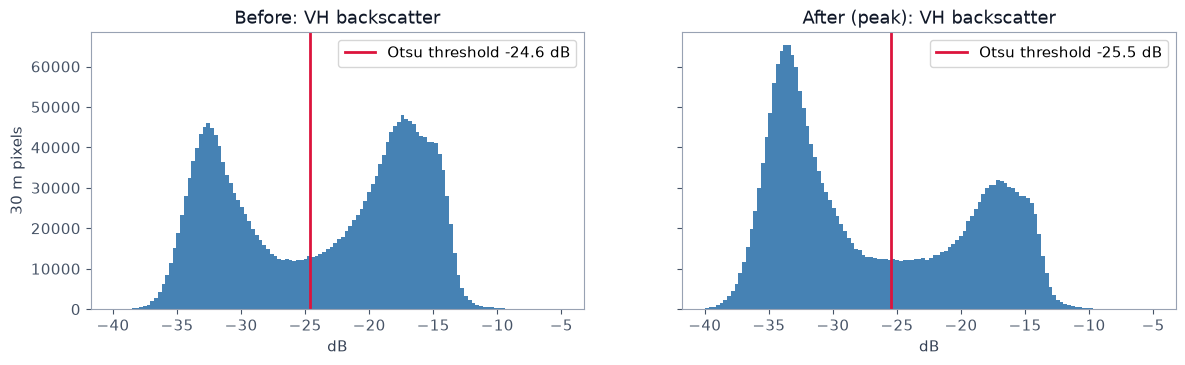

Open water: 44% of pixels before, 60% after


% of pixels (change-detection map),flagged,not flagged
this notebook,,
land at peak,18.1,22.1
water at peak,42.2,17.6


In [4]:
before, _, _ = dp.read_band(S1 / "output" / "sylhet_before_vh_db.tif")
after, _, _ = dp.read_band(S1 / "output" / "sylhet_after_vh_db.tif")
change, _, _ = dp.read_band(S1 / "output" / "sylhet_flood_extent.tif")
for arr in (before, after):
    arr[arr < -100] = np.nan  # -9999 fill outside the swath


def otsu(values, bins=256):
    """Otsu threshold: maximise the between-class variance of a 1-D sample."""
    v = values[np.isfinite(values)]
    hist, edges = np.histogram(v, bins=bins)
    centres = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist)
    w1 = w0[-1] - w0
    m0 = np.cumsum(hist * centres) / np.maximum(w0, 1)
    m1 = (np.sum(hist * centres) - np.cumsum(hist * centres)) / np.maximum(w1, 1)
    return float(centres[np.argmax(w0 * w1 * (m0 - m1) ** 2)])


T_BEFORE, T_AFTER = otsu(before), otsu(after)
water_before = np.where(np.isfinite(before), before < T_BEFORE, np.nan)
water_after = np.where(np.isfinite(after), after < T_AFTER, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, arr, t, name in zip(axes, (before, after), (T_BEFORE, T_AFTER), ("Before", "After (peak)")):
    ax.hist(arr[np.isfinite(arr)], bins=120, range=(-40, -5), color="steelblue")
    ax.axvline(t, color="crimson", lw=2, label=f"Otsu threshold {t:.1f} dB")
    ax.set_title(f"{name}: VH backscatter")
    ax.set_xlabel("dB")
    ax.legend()
axes[0].set_ylabel("30 m pixels")
plt.show()

ok = np.isfinite(water_before) & np.isfinite(water_after) & np.isfinite(change)
tab = pd.crosstab(pd.Series(np.where(water_after[ok] == 1, "water at peak", "land at peak"), name="this notebook"),
                  pd.Series(np.where(change[ok] == 1, "flagged", "not flagged"), name="change-detection map"),
                  normalize=True) * 100
print(f"Open water: {np.nanmean(water_before):.0%} of pixels before, {np.nanmean(water_after):.0%} after")
display(tab.round(1).rename_axis(columns="% of pixels (change-detection map)"))

**Reading the comparison.** About two thirds of the pixels agree. The two groups that disagree are the reason for rebuilding the inventory: *water at peak but not flagged* are mostly haors already flooded on the first date, and *flagged but land at peak* are fields that became wetter or darker without standing water. Both maps are shown below.

### From 30 m pixels to 250 m labels

Each 250 m cell gets its **flooded fraction**, the share of its 30 m pixels that are water at the peak (computed with `block_fraction`, which resamples to 50 m and averages 5 x 5 blocks). A cell is labelled

- **flooded** if at least half of it is water,
- **dry** if at most 10 % is water,
- and left out of training if it is in between (mixed cells along flood edges).

There is no separate permanent-water mask. In the haor basin almost all water in May and June is seasonal: the same beds carry boro rice from January to April. The dry-season NDVI check below confirms it.

Flooded cells: 18,695  dry cells: 8,299  mixed (not used): 3,832
Share flooded among labelled cells: 69%


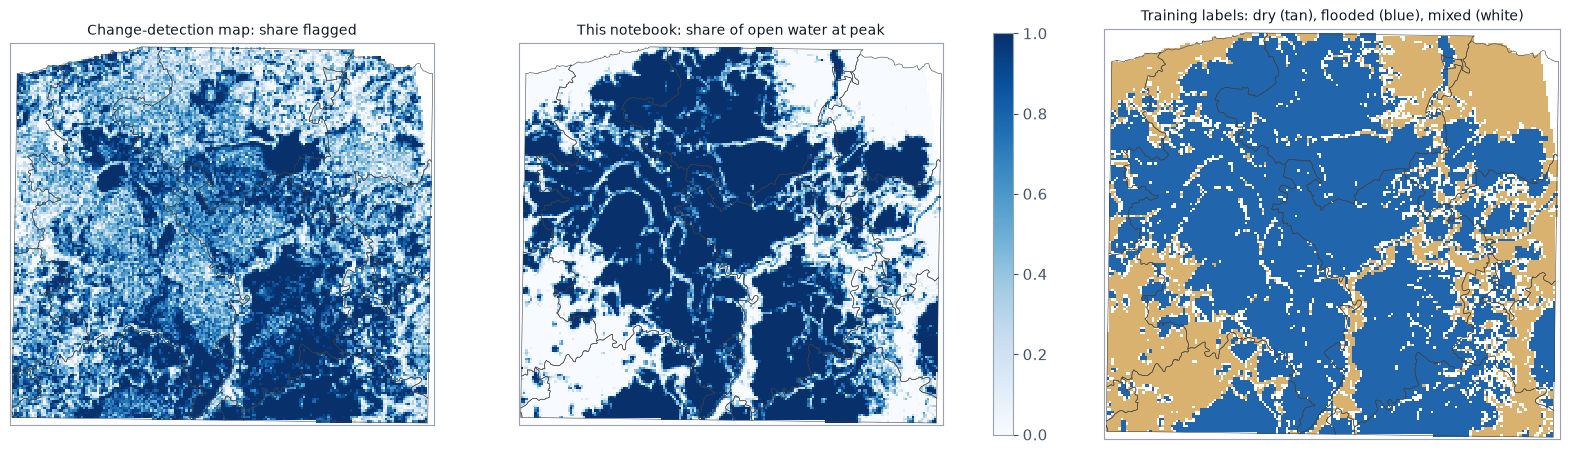

In [5]:
like = S1 / "output" / "sylhet_after_vh_db.tif"
FLOOD_FRAC = dp.block_fraction(water_after, like, GRID)
PRE_FRAC = dp.block_fraction(water_before, like, GRID)
CHANGE_FRAC = dp.block_fraction(np.where(np.isfinite(change), change, np.nan), like, GRID)
FLOOD_FRAC[~STUDY] = np.nan
PRE_FRAC[~STUDY] = np.nan

FLOOD_MIN, DRY_MAX = 0.5, 0.1


def make_labels(frac, flood_min=FLOOD_MIN, dry_max=DRY_MAX):
    """1 = flooded, 0 = dry, NaN = mixed or outside the study area."""
    lab = np.full(frac.shape, np.nan)
    lab[frac >= flood_min] = 1
    lab[frac <= dry_max] = 0
    lab[~STUDY | ~np.isfinite(frac)] = np.nan
    return lab


LABEL = make_labels(FLOOD_FRAC)
n_f, n_d = int(np.nansum(LABEL == 1)), int(np.nansum(LABEL == 0))
print(f"Flooded cells: {n_f:,}  dry cells: {n_d:,}  mixed (not used): {int(STUDY.sum() - n_f - n_d):,}")
print(f"Share flooded among labelled cells: {n_f / (n_f + n_d):.0%}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
show(axes[0], CHANGE_FRAC, "Change-detection map: share flagged", "Blues", 0, 1)
im = show(axes[1], FLOOD_FRAC, "This notebook: share of open water at peak", "Blues", 0, 1)
plt.colorbar(im, ax=axes[:2], fraction=0.02)
cm = ListedColormap(["#d9b26f", "#2166ac"])
show(axes[2], LABEL, "Training labels: dry (tan), flooded (blue), mixed (white)", cm, 0, 1)
plt.show()

**What the inventory says.** About three fifths of the basin was under open water at the peak. Dry land is confined to the north-east and north-west corners at the foot of the hills, the levees along the main channels, and the higher ground in the south-west. This high prevalence is unusual for a flood study, where flooded cells are normally a small minority; Section 10 handles it with class weights instead of discarding data.

## Rainfall context

The rainfall table holds **dekadal** (10-day) CHIRPS rainfall averaged over each district from 1981 to 2026, with the 1981 to 2020 average for the same dekad (`rfh_avg`). The AOI lies in Sunamganj (`BD6090`) and Netrakona (`BD4572`).

Rainfall is **not** used as a cell-level factor. Two district values cannot describe variation inside a 40 km window, and the water that fills the haors falls mostly upstream on the Meghalaya plateau, outside the AOI. It is shown here to describe the event that produced the inventory.

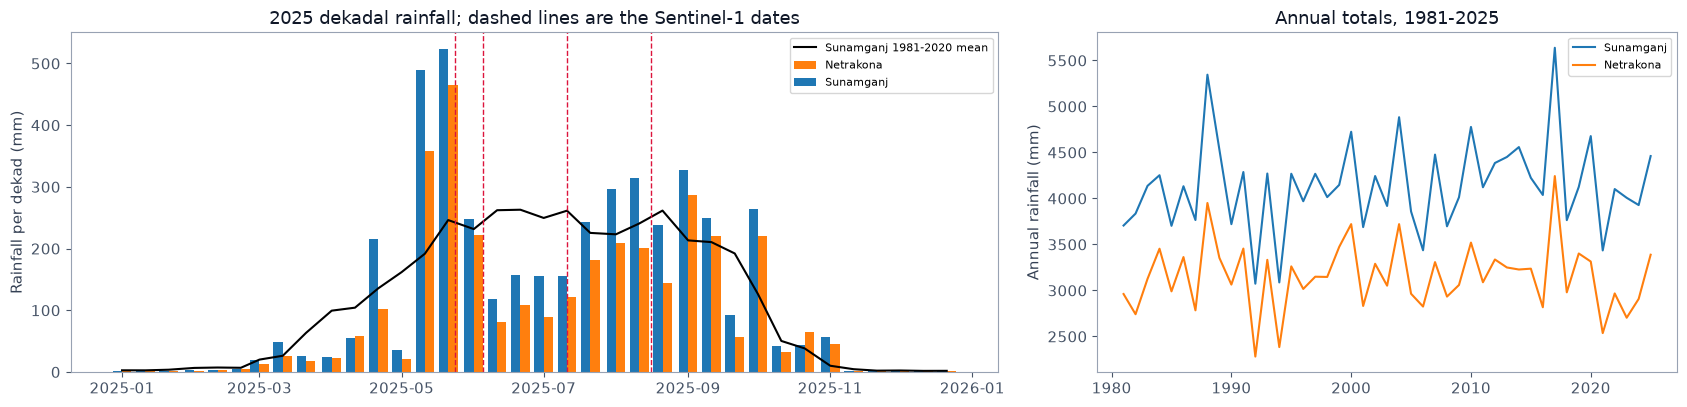

,May 2025 (mm),May normal (mm),ratio
district,,,
Netrakona,844.069,489.577,1.724
Sunamganj,1049.097,599.750,1.749


Mean annual rainfall 1981-2025 (mm): {'Netrakona': 3153.0, 'Sunamganj': 4136.0}


In [6]:
rain = pd.read_csv(BD / "bgd-rainfall-subnat-full.csv", parse_dates=["date"])
DISTRICTS = {"BD6090": "Sunamganj", "BD4572": "Netrakona"}
rain = rain[rain.PCODE.isin(DISTRICTS)].assign(district=lambda d: d.PCODE.map(DISTRICTS))
S1_DATES = pd.to_datetime(["2025-05-24", "2025-06-05", "2025-07-11", "2025-08-16"])

fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
r25 = rain[rain.date.dt.year == 2025]
COLORS = {"Sunamganj": "tab:blue", "Netrakona": "tab:orange"}
for name, g in r25.groupby("district"):
    axes[0].bar(g.date + pd.Timedelta(days=2 if name == "Netrakona" else -2), g.rfh, width=4, label=name,
                color=COLORS[name])
g = r25[r25.district == "Sunamganj"]
axes[0].plot(g.date, g.rfh_avg, color="black", lw=1.5, label="Sunamganj 1981-2020 mean")
for d in S1_DATES:
    axes[0].axvline(d, color="crimson", ls="--", lw=1)
axes[0].set_ylabel("Rainfall per dekad (mm)")
axes[0].set_title("2025 dekadal rainfall; dashed lines are the Sentinel-1 dates")
axes[0].legend(fontsize=8)

annual = (rain[(rain.date.dt.year >= 1981) & (rain.date.dt.year <= 2025)]
          .groupby([rain.date.dt.year, "district"]).rfh.sum().unstack())
for name, col in COLORS.items():
    axes[1].plot(annual.index, annual[name], color=col, label=name)
axes[1].set_ylabel("Annual rainfall (mm)")
axes[1].set_title("Annual totals, 1981-2025")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

may = r25[(r25.date >= "2025-05-01") & (r25.date < "2025-06-01")].groupby("district")[["rfh", "rfh_avg"]].sum()
display(may.assign(ratio=may.rfh / may.rfh_avg).rename(columns={"rfh": "May 2025 (mm)", "rfh_avg": "May normal (mm)"}))
print("Mean annual rainfall 1981-2025 (mm):", annual.mean().round(0).to_dict())

May 2025 brought about 1.7 times the normal May rainfall to both districts, almost all of it in the second and third dekads (11 to 31 May), each about twice its normal. That is the event behind the inventory: the first radar scene in the folder (24 May) comes just after the heaviest rain, and open water expands between the before and after images from 44 % to 60 % of the AOI.

## Conditioning factors

### Terrain and hydrology

All terrain factors come from the 250 m DEM, processed with the GeoLattice hydrology tools of Module 03.02:

| Factor | Meaning for flooding | Tool |
|---|---|---|
| `elev` | Lower land floods first | DEM |
| `hand` | Height above the nearest drainage line: how far water must rise to reach the cell | `fill_depressions`, `d8_pointer`, `d8_flow_accumulation`, `extract_streams`, `elevation_above_stream` |
| `depression` | Depth of the closed depression the cell sits in (filled minus original DEM): haor beds | `fill_depressions` |
| `slope` | Gentle slopes hold water | `slope` |
| `tpi` | Position relative to the mean elevation within about 10 km; negative in basins | `tpi` with a 41-cell window |
| `twi` | Topographic wetness index $\ln(a / \tan\beta)$ with D-infinity flow | `surface_hydrology.twi` |

The stream network for HAND uses a threshold of 1,000 cells (62.5 km²), which keeps the main rivers and drains of the basin. With smaller thresholds every haor gets its own channel and HAND loses contrast. Flow that leaves the 40 km window before it meets a stream is measured against the grid edge where it leaves.

In [7]:
t0 = time.time()
dem = dem_raw.copy()
bad = ~np.isfinite(dem) | (dem < 0)
idx = ndimage.distance_transform_edt(bad, return_distances=False, return_indices=True)
dem = dem[tuple(idx)]  # nearest-valid fill for artefacts and the area outside Bangladesh
F = OUT / "factors"
F.mkdir(exist_ok=True)
GRID.write(F / "dem.tif", dem)

fill_depressions(F / "dem.tif", F / "dem_filled.tif", overwrite=True)
d8_pointer(F / "dem_filled.tif", F / "d8.tif", overwrite=True)
d8_flow_accumulation(F / "dem_filled.tif", F / "flow_acc.tif", pointer=F / "d8.tif", overwrite=True)
extract_streams(F / "flow_acc.tif", F / "streams.tif", threshold=1000, overwrite=True)
# Flow that leaves the grid before meeting a stream has no HAND reference. The grid edge is
# treated as drainage too, so that every cell gets a height above its outlet.
st = np.nan_to_num(dp.read_band(F / "streams.tif")[0]) > 0
edge = np.zeros(GRID.shape, bool)
edge[[0, -1], :] = edge[:, [0, -1]] = True
GRID.write(F / "streams_and_edge.tif", (st | edge).astype(float), dtype="float32")
elevation_above_stream(F / "dem_filled.tif", F / "streams_and_edge.tif", F / "d8.tif", F / "hand.tif",
                       overwrite=True)
slope(F / "dem.tif", F / "slope.tif", overwrite=True, compute_edges=True)
tpi(F / "dem.tif", F / "tpi.tif", window_size=41, overwrite=True)
surface_hydrology.twi(F / "dem_filled.tif", F / "twi.tif", overwrite=True)


def read(path):
    return dp.read_band(path)[0]


FACT = {
    "elev": dem,
    "hand": np.maximum(read(F / "hand.tif"), 0),
    "depression": np.maximum(read(F / "dem_filled.tif") - dem, 0),
    "slope": read(F / "slope.tif"),
    "tpi": read(F / "tpi.tif"),
    "twi": read(F / "twi.tif"),
}
streams = read(F / "streams.tif") > 0
print(f"Terrain factors in {time.time() - t0:.1f} s; stream cells: {streams.sum():,}")
display(pd.DataFrame({k: pd.Series(v[STUDY]).describe() for k, v in FACT.items()}).T.round(2))

Terrain factors in 0.9 s; stream cells: 619


,count,mean,std,min,25%,50%,75%,max
elev,30826.0,8.23,2.73,0.00,6.50,7.88,9.63,35.29
hand,30826.0,1.72,2.06,0.00,0.02,1.01,2.61,28.58
depression,30826.0,0.47,0.92,0.00,0.00,0.00,0.62,7.00
slope,30826.0,0.20,0.13,0.00,0.10,0.17,0.26,2.54
tpi,30826.0,-0.04,1.69,-7.91,-1.10,-0.14,0.91,24.86
twi,30826.0,13.56,2.73,8.69,11.55,12.56,14.99,26.22


### River network

The LGED river layer maps every river and khal (canal) of the country. Two factors come from it: **distance to the nearest mapped channel** and **drainage density** (km of channel per km² in a 2.75 km window).

In [8]:
bbox_wgs = tuple(gpd.read_file(S1 / "sylhet_aoi.geojson").buffer(0.05).total_bounds)
rivers = gpd.read_file(BD / "bgd_hyd_rivers_lged" / "bgd_hyd_rivers_lged.shp", bbox=bbox_wgs).to_crs(GRID.crs)
river_cells = dp.rasterize_geometries(rivers.geometry, GRID)
FACT["dist_river"] = ndimage.distance_transform_edt(river_cells == 0) * GRID.res
FACT["drain_density"] = ndimage.uniform_filter(river_cells.astype(float), size=11) * GRID.res / 1000 / 0.0625
print(f"{len(rivers):,} channel segments, {rivers.length.sum() / 1000:,.0f} km; "
      f"{river_cells[STUDY].mean():.0%} of study cells contain a channel")

1,370 channel segments, 3,149 km; 24% of study cells contain a channel


A quarter of all cells contain a mapped channel: in the haors the network is so dense that nearly every cell is within a few hundred metres of one. Section 7 shows what that does to these two factors.

### Soil and land

The national soil-survey rasters are categorical. Their codes are documented in `IDFILES/`.

| Factor | Classes in the AOI | Use |
|---|---|---|
| `LT` land type | Highland, Medium highland 1 and 2, Medium lowland, Lowland, Very lowland | The soil survey's classification of **normal seasonal flooding depth**. See the leakage note below. |
| `DRC` drainage class | Imperfectly to very poorly drained | Factor |
| `SPC` permeability | Slow to rapid, and mixed classes | Factor (ML only) |
| `TEX` texture | Codes without a lookup table | Factor (ML only) |
| `LU` land use 2020 | Codes 0, 2, 3, 4, 6, 7 | Factor (ML only); no legend in the folder |
| `HFC`, `SDC`, `STYPE`, `AEZ` | Slope class, depth class, general soil type, agro-ecological zone | Mapped, not modelled: slope is already a terrain factor, the meaning of SDC is unconfirmed, and soil type and AEZ are mostly one class in this window |

**A leakage risk.** Land type is defined from how deep land is normally flooded. Used as a predictor, it partly hands the model the answer. Every machine-learning model is therefore fitted **with and without** land type, and the multi-criteria model leaves it out and uses it instead as an independent check (Section 12).

In [9]:
CAT = {name: to_grid(BD / f"{name}.tif") for name in ["LT", "DRC", "SPC", "TEX", "HFC", "SDC", "STYPE", "AEZ"]}
CAT["LU"] = to_grid(BD / "landuse_2020.tif")
LT_NAMES = pd.read_csv(BD / "IDFILES" / "LT_ID.csv").set_index("LT_ID").LT_Class.to_dict()
DRC_NAMES = pd.read_csv(BD / "IDFILES" / "DRC_ID.csv").set_index("DRC").DRC_CLASS.to_dict()

rows = []
for name, arr in CAT.items():
    vals, cnt = np.unique(arr[STUDY & np.isfinite(arr)], return_counts=True)
    rows.append((name, len(vals), f"{cnt.max() / cnt.sum():.0%}", int(vals[np.argmax(cnt)])))
display(pd.DataFrame(rows, columns=["layer", "classes", "largest class share", "largest class code"]))

,layer,classes,largest class share,largest class code
0,LT,7,35%,5
1,DRC,7,30%,12
2,SPC,11,78%,11
3,TEX,9,69%,15
4,HFC,13,49%,2
5,SDC,11,42%,14
6,STYPE,6,45%,6
7,AEZ,5,67%,21
8,LU,6,72%,2


### Vegetation and groundwater before the monsoon

The NDVI and water-table series are 16-day composites for **2020**, not 2025. They describe the usual seasonal state of each cell, which is what a susceptibility factor should do. Values *during* the flood would give the answer away (water has low NDVI and a water table at the surface), so only the dry season is used:

- `ndvi_dry`: mean NDVI from 1 January to 21 March (day 1 to 81), the boro rice season;
- `wt_premonsoon`: mean depth to the water table from 21 March to 8 May (day 81 to 129), its seasonal low.

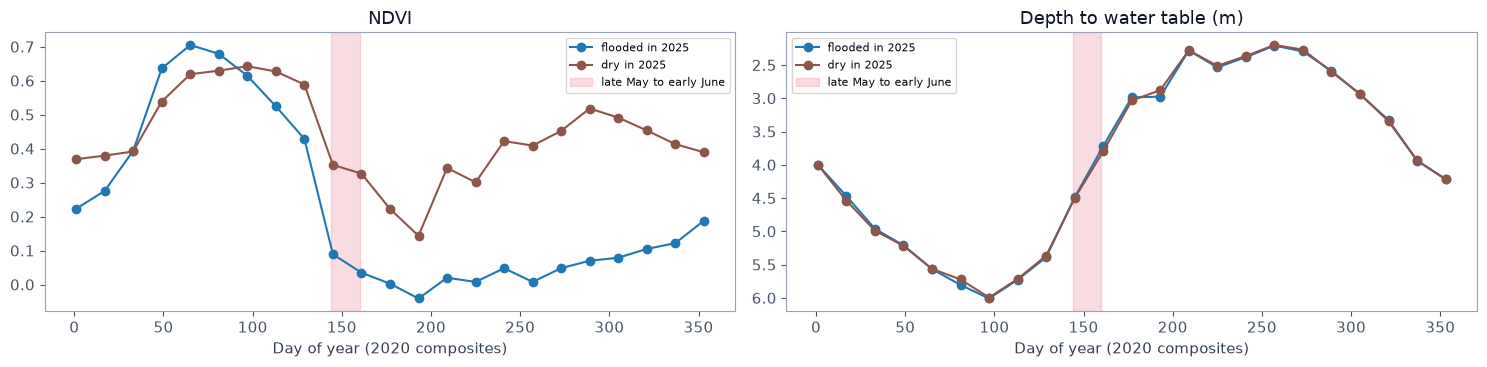

Cells under water on both radar dates: 12,971; their mean dry-season NDVI is 0.48 (dry cells: 0.49)


In [10]:
DOY = [1 + 16 * i for i in range(23)]
ndvi = np.stack([to_grid(BD / "NDVI" / f"ndvi_2020_{d}.tif", "bilinear", TM_WKT) for d in DOY]) / 1e4
wt = np.stack([to_grid(BD / "Watertable_2020" / f"watertable_2020_{d:03d}.tif", "bilinear", TM_WKT) for d in DOY])
wt[wt < -100] = np.nan
FACT["ndvi_dry"] = np.nanmean(ndvi[:6], axis=0)  # day 1 to 81
FACT["wt_premonsoon"] = np.nanmean(wt[5:9], axis=0)  # day 81 to 129
FACT["wt_premonsoon"] = np.where(np.isfinite(FACT["wt_premonsoon"]), FACT["wt_premonsoon"],
                                 np.nanmedian(FACT["wt_premonsoon"][STUDY]))

flooded, dry = LABEL == 1, LABEL == 0
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, stack, name in zip(axes, (ndvi, wt), ("NDVI", "Depth to water table (m)")):
    for m, lab, col in ((flooded, "flooded in 2025", "tab:blue"), (dry, "dry in 2025", "tab:brown")):
        ax.plot(DOY, [np.nanmean(s[m]) for s in stack], "o-", color=col, label=lab)
    ax.axvspan(144, 160, color="crimson", alpha=0.15, label="late May to early June")
    ax.set_xlabel("Day of year (2020 composites)")
    ax.set_title(name)
    ax.legend(fontsize=8)
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

both = (water_before == 1) & (water_after == 1)
both250 = dp.block_fraction(np.where(np.isfinite(water_before), both, np.nan), like, GRID) >= 0.5
print(f"Cells under water on both radar dates: {np.sum(both250 & STUDY):,}; "
      f"their mean dry-season NDVI is {np.nanmean(FACT['ndvi_dry'][both250 & STUDY]):.2f} "
      f"(dry cells: {np.nanmean(FACT['ndvi_dry'][dry]):.2f})")

**Two readings.** Cells that flooded in 2025 are as green as the dry cells in January to March, the boro season, and lose their NDVI from May. Even cells under water on *both* radar dates carry crops in the dry season, so they are seasonal floodplain, not permanent water bodies, which justifies keeping them in the inventory. The water table over the basin is shallow everywhere and reaches the surface in the monsoon; its pre-monsoon depth varies little across the window.

### All factors

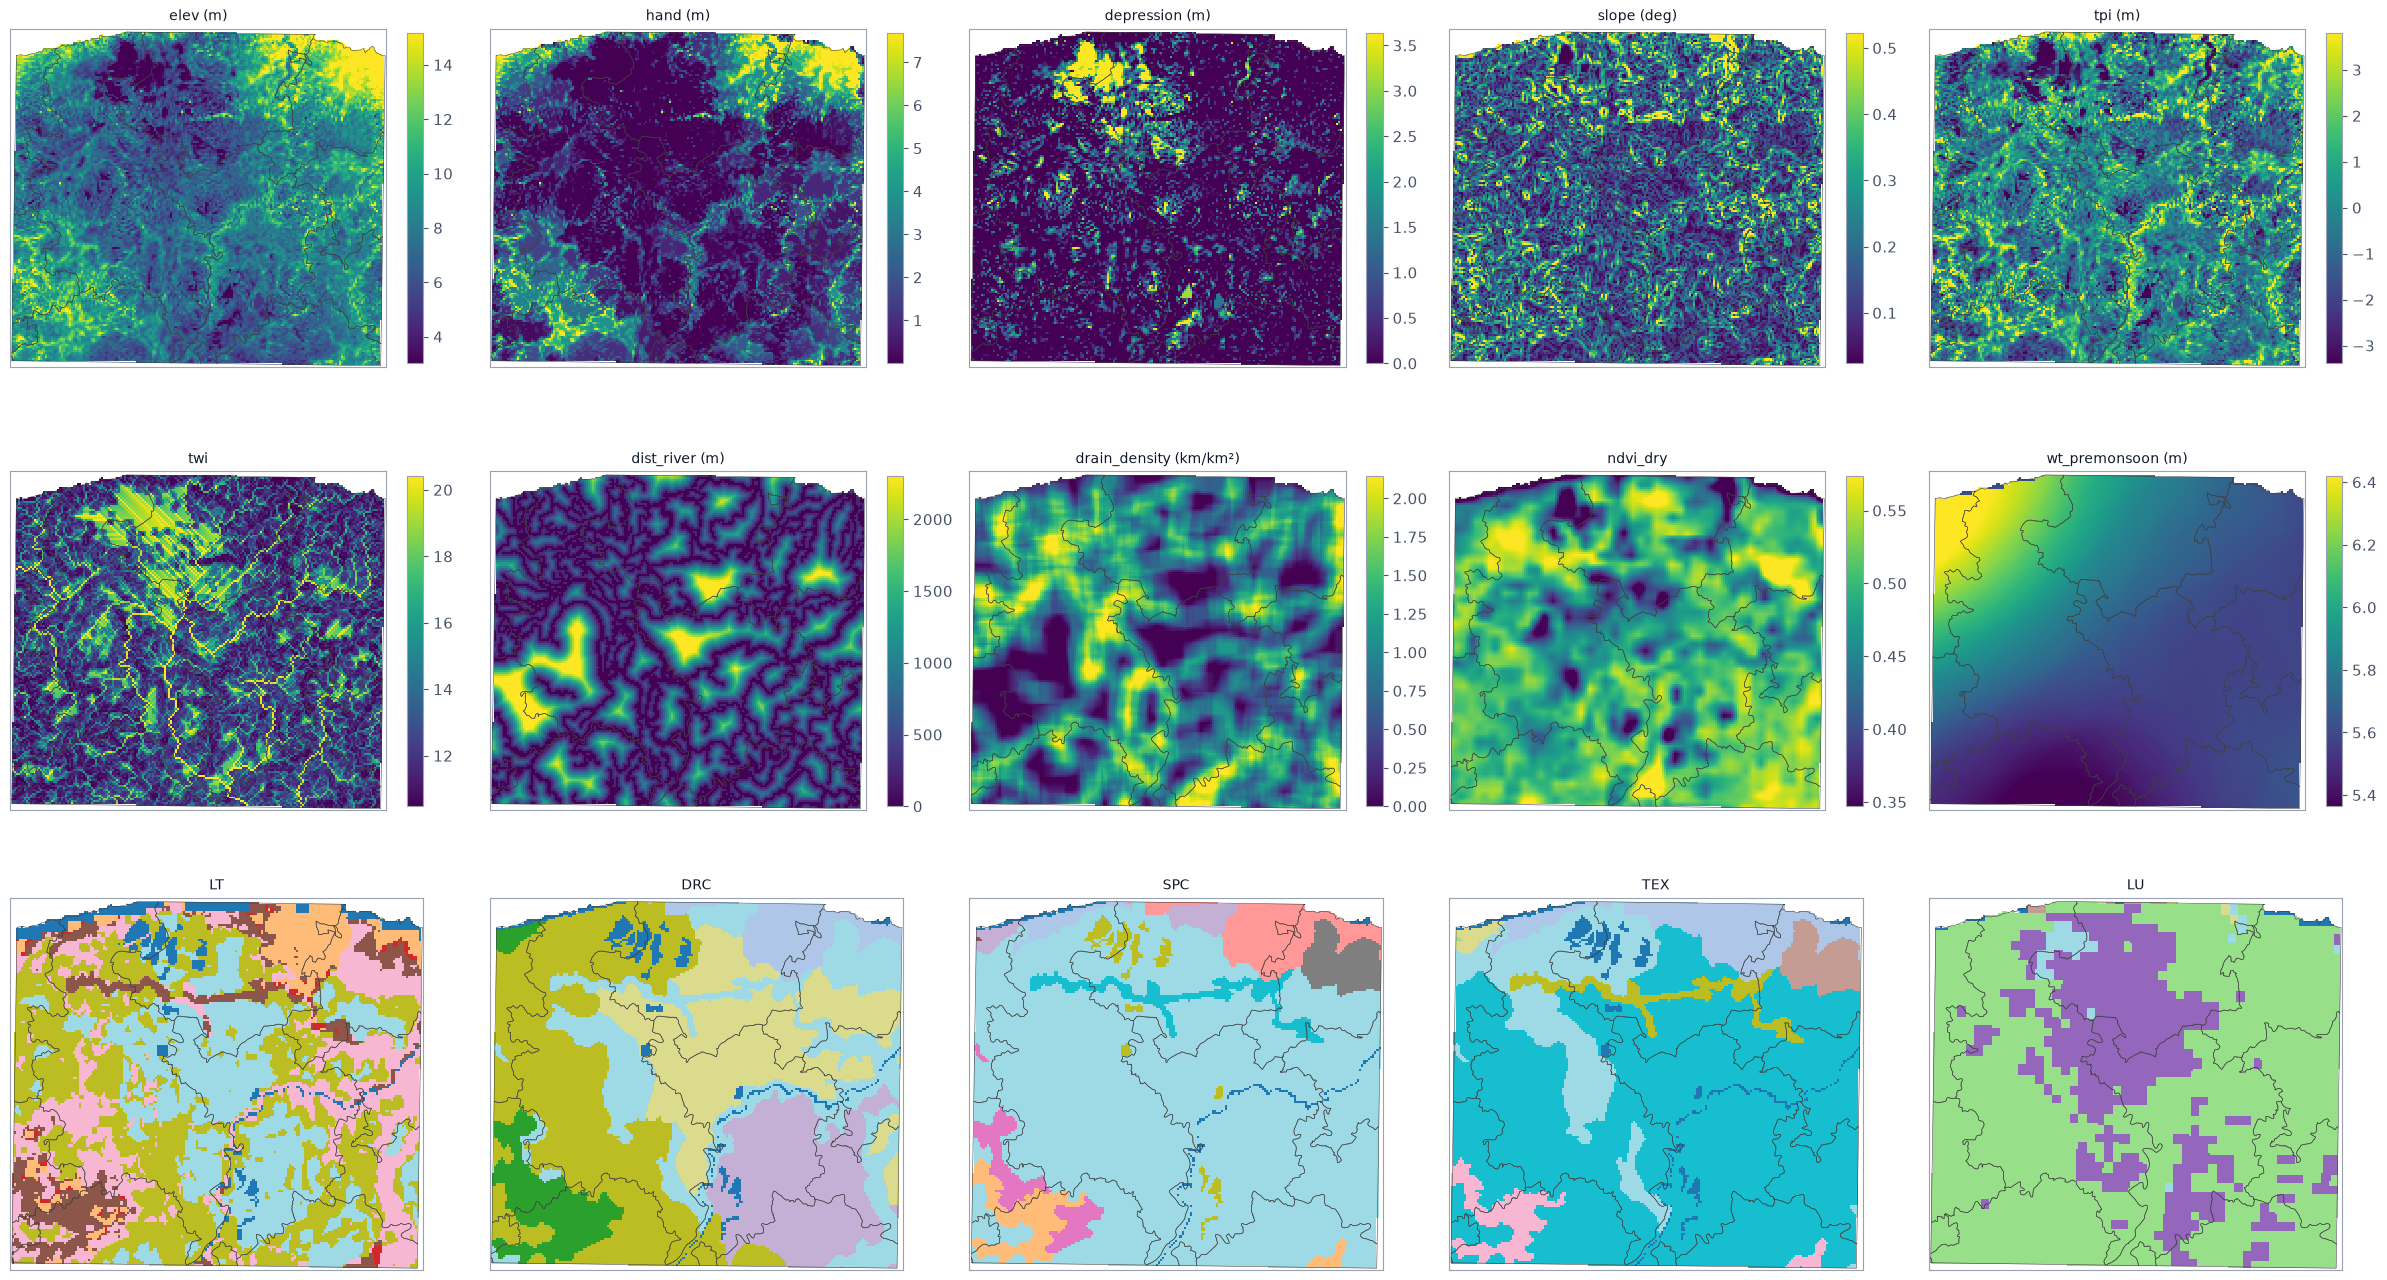

In [11]:
NUM = ["elev", "hand", "depression", "slope", "tpi", "twi", "dist_river", "drain_density", "ndvi_dry", "wt_premonsoon"]
UNITS = {"elev": "m", "hand": "m", "depression": "m", "slope": "deg", "tpi": "m", "twi": "", "dist_river": "m",
         "drain_density": "km/km²", "ndvi_dry": "", "wt_premonsoon": "m"}
fig, axes = plt.subplots(3, 5, figsize=(24, 13.5))
for ax, k in zip(axes.ravel(), NUM):
    v = FACT[k][STUDY]
    im = show(ax, FACT[k], f"{k} ({UNITS[k]})" if UNITS[k] else k, "viridis",
              *np.nanpercentile(v, [2, 98]))
    plt.colorbar(im, ax=ax, fraction=0.04)
for ax, k in zip(axes.ravel()[len(NUM):], ["LT", "DRC", "SPC", "TEX", "LU"]):
    show(ax, CAT[k], k, "tab20")
plt.tight_layout()
plt.show()

## Factor screening

### How well does each factor separate flooded from dry cells on its own?

The **single-factor AUC** is the probability that a randomly chosen flooded cell has a more flood-prone value than a randomly chosen dry cell. 0.5 means no information. The direction is chosen so that AUC is at least 0.5, and reported.

In [12]:
LAB = np.isfinite(LABEL)
y_lab = LABEL[LAB].astype(int)
rows = []
for k in NUM + ["LT", "DRC"]:
    v = (FACT.get(k) if k in FACT else CAT[k])[LAB]
    ok_ = np.isfinite(v)
    auc = roc_auc_score(y_lab[ok_], v[ok_])
    rows.append((k, max(auc, 1 - auc), "higher = more flooding" if auc >= 0.5 else "lower = more flooding"))
single = pd.DataFrame(rows, columns=["factor", "AUC", "direction"]).sort_values("AUC", ascending=False)
display(single.set_index("factor"))

,AUC,direction
factor,,
elev,0.932,lower = more flooding
hand,0.901,lower = more flooding
LT,0.859,higher = more flooding
twi,0.740,higher = more flooding
tpi,0.698,lower = more flooding
depression,0.672,higher = more flooding
slope,0.617,lower = more flooding
DRC,0.590,higher = more flooding
wt_premonsoon,0.551,higher = more flooding


Elevation and HAND carry most of the signal, followed by land type and the position in the basin. The two river-network factors are almost uninformative: when channels run through every haor, *distance to a channel* no longer separates high from low land. They are kept in the machine-learning models, which can ignore them, but left out of the expert model.

### Redundancy

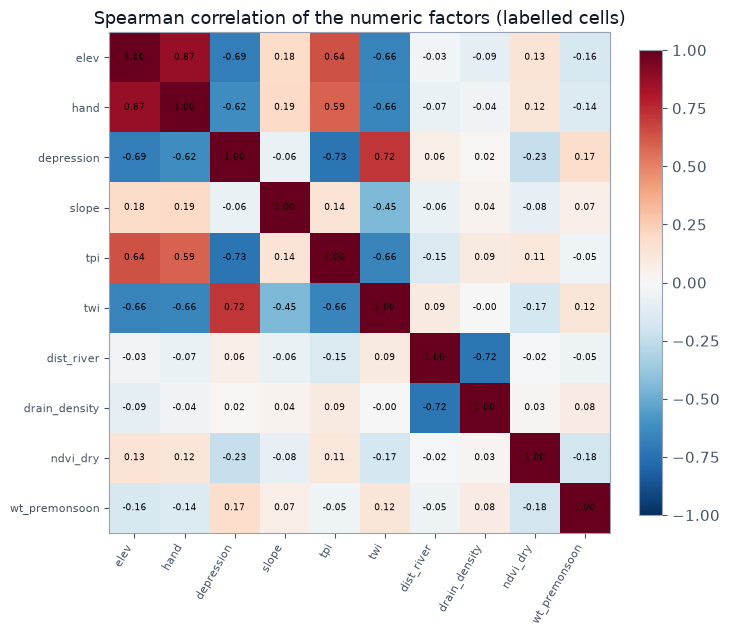

,elev,hand,depression,slope,tpi,twi,dist_river,drain_density,ndvi_dry,wt_premonsoon
VIF,9.8,7.21,3.36,1.25,2.46,2.0,2.22,2.29,1.23,1.11


In [13]:
Xs = pd.DataFrame({k: FACT[k][LAB] for k in NUM})
corr = Xs.corr(method="spearman")
Z = (Xs - Xs.mean()) / Xs.std()
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(Z.values, rowvar=False))), index=NUM, name="VIF")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(NUM)), NUM, fontsize=8)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
plt.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Spearman correlation of the numeric factors (labelled cells)")
plt.show()
display(vif.round(2).to_frame().T)

Elevation, HAND and TPI are strongly correlated, as expected: all three measure how high a cell sits. Variance inflation factors stay below the usual alarm level of 10 (elevation comes closest, at about 9.8), so all are kept. Tree models are not hurt by correlated predictors; for the logistic model it means the individual coefficients should not be interpreted.

### Frequency ratio by class

The **frequency ratio** (FR) of a class is the share of flooded cells that fall in the class divided by the share of all labelled cells that fall in it. FR > 1 means the class floods more often than average. Continuous factors are split into deciles of the study area.

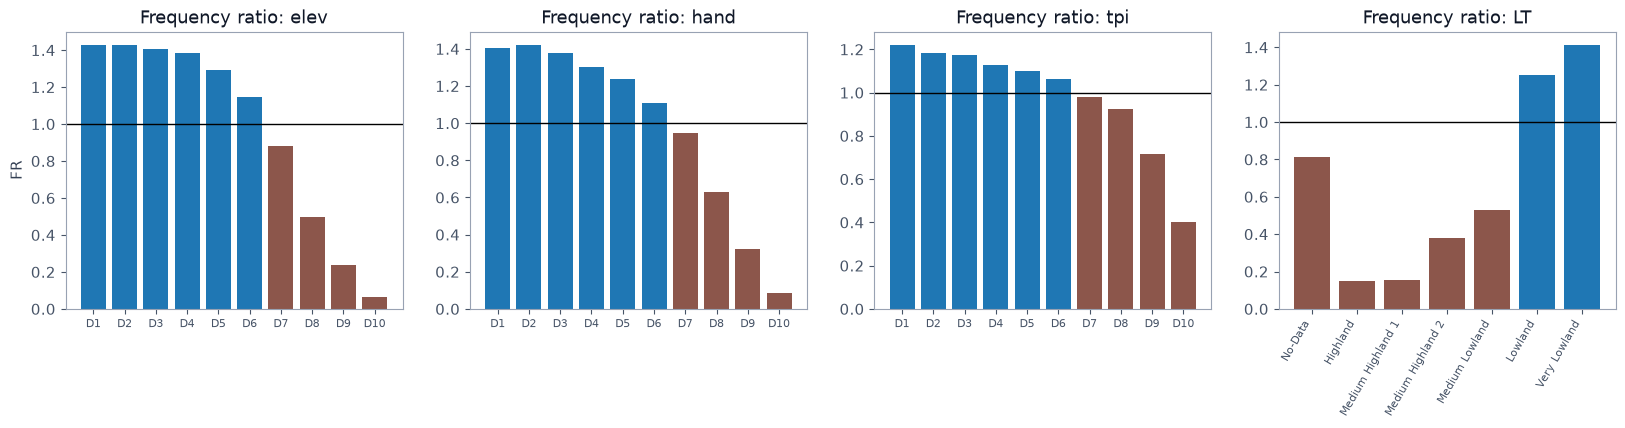

In [14]:
def classes_of(name):
    """Integer classes: deciles for continuous factors, codes for categorical ones."""
    if name in CAT:
        return np.where(np.isfinite(CAT[name]), CAT[name], -1).astype(int)
    v = FACT[name]
    edges = np.unique(np.nanpercentile(v[STUDY], np.arange(10, 100, 10)))
    return np.digitize(v, edges)


FR_FACTORS = ["elev", "hand", "depression", "slope", "tpi", "twi", "ndvi_dry", "wt_premonsoon", "LT", "DRC", "SPC",
              "TEX", "LU"]
CLASSES = {k: classes_of(k) for k in FR_FACTORS}


def fr_table(name, mask):
    """Frequency ratio of each class of one factor, from the labelled cells inside ``mask``."""
    c, lab = CLASSES[name][mask & LAB], LABEL[mask & LAB]
    df = pd.DataFrame({"c": c, "y": lab}).groupby("c").y.agg(["sum", "count"])
    share_f = (df["sum"] + 0.5) / (df["sum"].sum() + 0.5 * len(df))  # add-half smoothing for empty classes
    share_a = df["count"] / df["count"].sum()
    return np.log(share_f / share_a)  # log FR: 0 = average, > 0 = floods more often


fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
for ax, k in zip(axes, ["elev", "hand", "tpi", "LT"]):
    t = np.exp(fr_table(k, STUDY))
    labels = [LT_NAMES.get(i, i) for i in t.index] if k == "LT" else [f"D{i + 1}" for i in t.index]
    ax.bar(range(len(t)), t.values, color=np.where(t.values > 1, "tab:blue", "tab:brown"))
    ax.axhline(1, color="black", lw=1)
    ax.set_xticks(range(len(t)), labels, rotation=60 if k == "LT" else 0, ha="right" if k == "LT" else "center",
                  fontsize=8)
    ax.set_title(f"Frequency ratio: {k}")
axes[0].set_ylabel("FR")
plt.show()

The lowest elevation and HAND deciles reach a frequency ratio of about 1.4, close to the ceiling of 1.45 that a 69 % flooded share allows (1 / 0.69): nearly every cell there flooded. The top deciles almost never did. Land type behaves as the soil survey intends: highland is rarely flooded, very lowland nearly always.

## Model 1: frequency ratio

The **flood susceptibility index** (FSI) of a cell is the sum of the log frequency ratios of its classes over all factors. It is the simplest data-driven model: each factor is judged on its own and the evidence is added. Land type is left out, for the leakage reason given in Section 6.3.

The machine-learning models in Section 10 are tested on **5 km blocks** they did not see. For a fair comparison the frequency ratios are recomputed from the training blocks of each fold in the same way, in Section 10.2; here they are fitted on all labelled cells to draw the map.

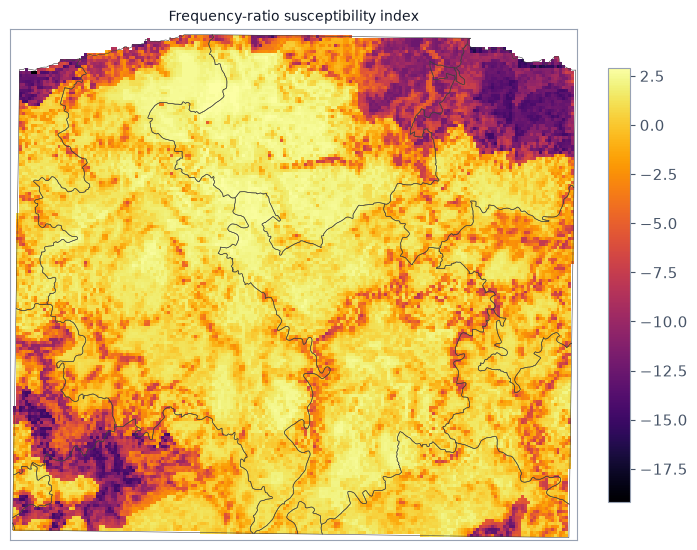

In [15]:
FR_USE = [k for k in FR_FACTORS if k != "LT"]


def fsi(mask_fit):
    """Flood susceptibility index for every cell, with frequency ratios from ``mask_fit``."""
    out = np.zeros(GRID.shape)
    for k in FR_USE:
        t = fr_table(k, mask_fit)
        out += pd.Series(CLASSES[k].ravel()).map(t).fillna(0).values.reshape(GRID.shape)
    return out


SCORE = {"FrequencyRatio": fsi(STUDY)}
fig, ax = plt.subplots(figsize=(8, 7))
im = show(ax, SCORE["FrequencyRatio"], "Frequency-ratio susceptibility index", "inferno")
plt.colorbar(im, ax=ax, fraction=0.035)
plt.show()

## Model 2: AHP multi-criteria model

The expert model does not look at the inventory. Each criterion is turned into a **fuzzy membership** between 0 (not flood-prone) and 1 (highly flood-prone), and the memberships are combined with weights from the **Analytic Hierarchy Process** (AHP).

| Criterion | Membership | Reasoning |
|---|---|---|
| `elev` | `small`, midpoint 9 m | the basin floor lies at 2 to 8 m; levees and terraces above 10 m |
| `hand` | `small`, midpoint 2 m | a 2 m rise above the nearest drain is a common monsoon stage |
| `depression` | `linear`, 0 to 3 m | closed depressions hold water until it evaporates or is pumped |
| `tpi` | `small`, midpoint -1 m | below the 10 km mean elevation |
| `twi` | `large`, midpoint 10 | wet, convergent cells |
| `drainage` | class scores | poorly and very poorly drained soils stay wet |

The judgments put the two measures of relative height first, as the flood literature for deltas does.

In [16]:
CRITERIA = ["hand", "elev", "depression", "tpi", "drainage", "twi"]
JUDGMENTS = {
    ("hand", "elev"): 1, ("hand", "depression"): 2, ("hand", "tpi"): 3, ("hand", "drainage"): 4, ("hand", "twi"): 5,
    ("elev", "depression"): 2, ("elev", "tpi"): 3, ("elev", "drainage"): 4, ("elev", "twi"): 5,
    ("depression", "tpi"): 2, ("depression", "drainage"): 3, ("depression", "twi"): 3,
    ("tpi", "drainage"): 2, ("tpi", "twi"): 2,
    ("drainage", "twi"): 1,
}
RANDOM_INDEX = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}


def ahp(criteria, judgments):
    """AHP weights (principal eigenvector) and consistency ratio for a reciprocal matrix."""
    n = len(criteria)
    A = np.ones((n, n))
    for (a, b), v in judgments.items():
        i, j = criteria.index(a), criteria.index(b)
        A[i, j], A[j, i] = v, 1.0 / v
    vals, vecs = np.linalg.eig(A)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    w = w / w.sum()
    ci = (vals[k].real - n) / (n - 1)
    return pd.Series(w, index=criteria), A, ci / RANDOM_INDEX[n]


W_AHP, A_MATRIX, CR = ahp(CRITERIA, JUDGMENTS)
display(pd.DataFrame(A_MATRIX, index=CRITERIA, columns=CRITERIA).round(2))
display(W_AHP.rename("weight").to_frame().T.round(3))
print(f"Consistency ratio: {CR:.3f} ({'acceptable' if CR < 0.10 else 'revise the judgments'})")

,hand,elev,depression,tpi,drainage,twi
hand,1.00,1.00,2.00,3.0,4.0,5.0
elev,1.00,1.00,2.00,3.0,4.0,5.0
depression,0.50,0.50,1.00,2.0,3.0,3.0
tpi,0.33,0.33,0.50,1.0,2.0,2.0
drainage,0.25,0.25,0.33,0.5,1.0,1.0
twi,0.20,0.20,0.33,0.5,1.0,1.0


,hand,elev,depression,tpi,drainage,twi
weight,0.3,0.3,0.174,0.105,0.063,0.058


Consistency ratio: 0.005 (acceptable)


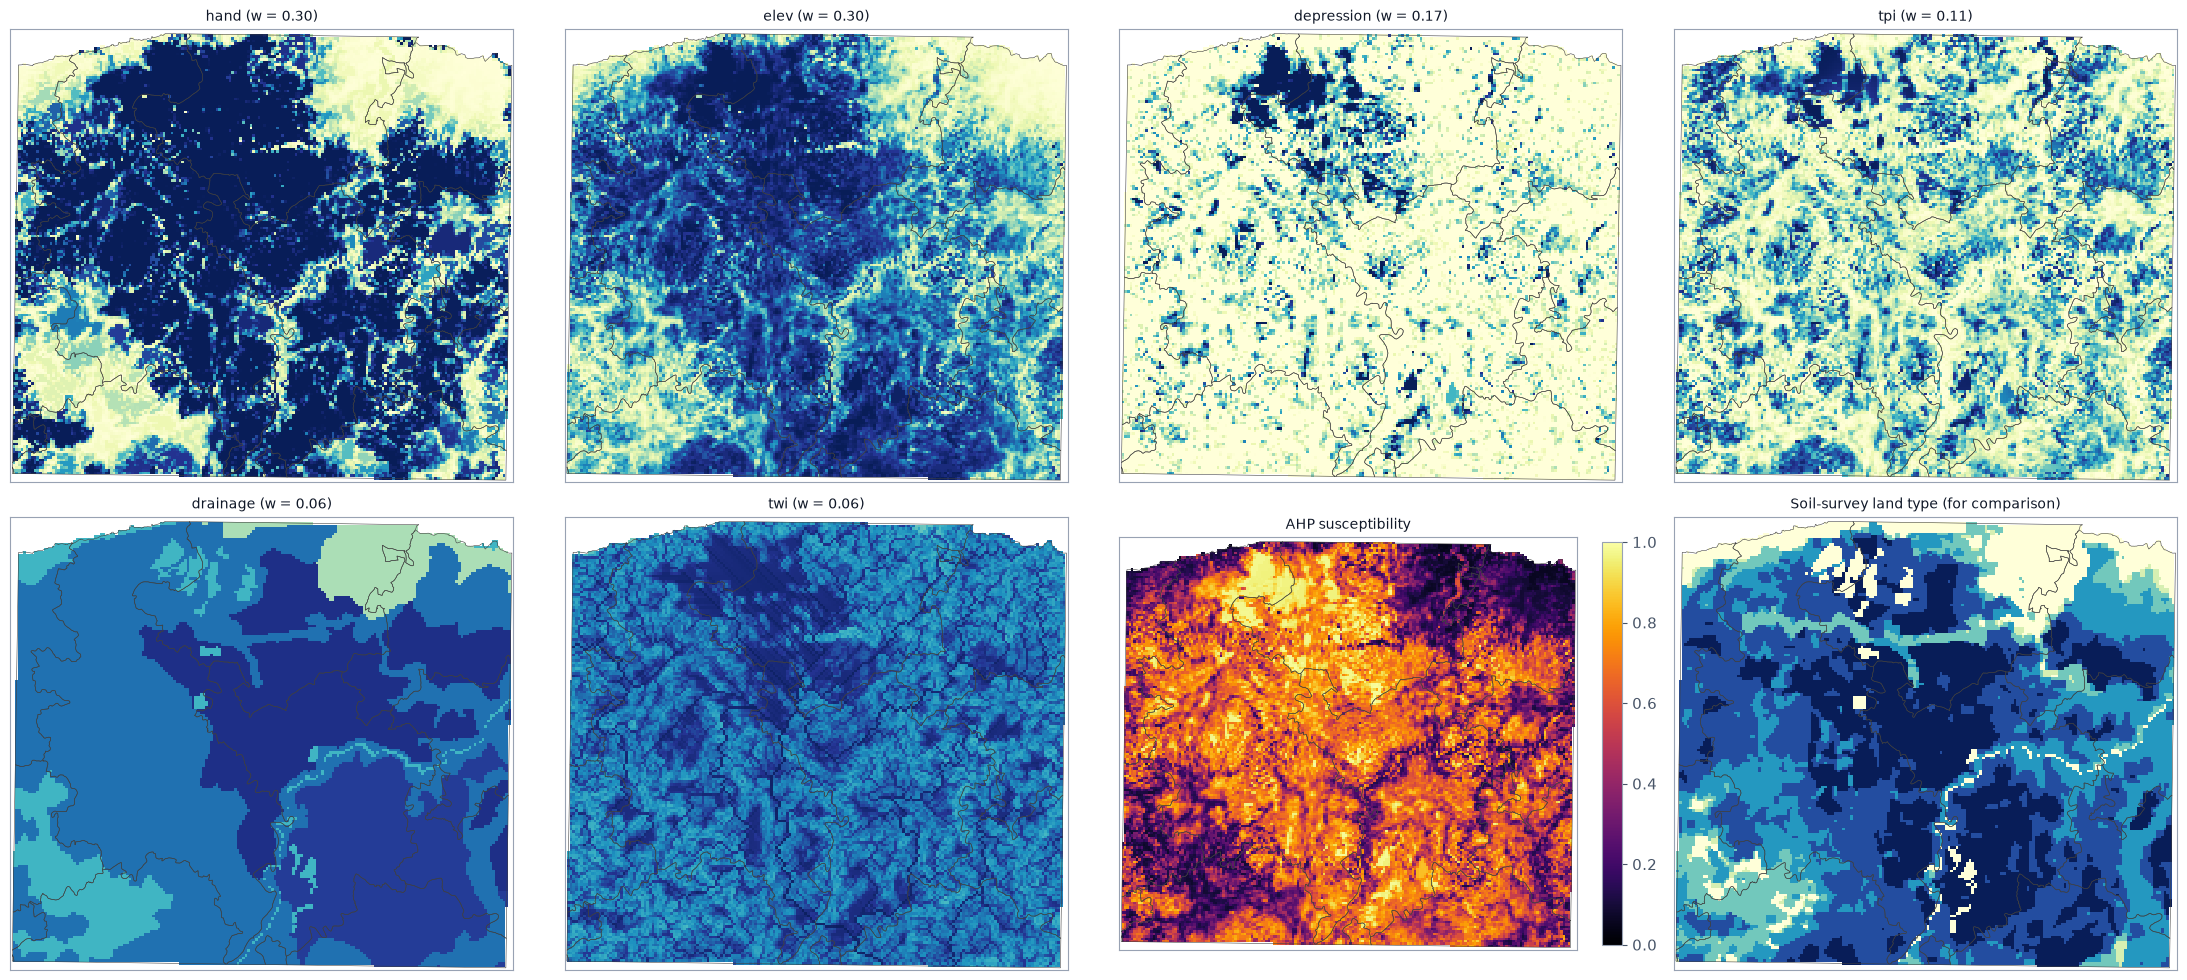

Spearman correlation of the AHP score with land type (1 = highland ... 6 = very lowland): 0.60


In [17]:
DRC_SCORE = {1: 0.3, 3: 0.5, 7: 0.85, 12: 0.7, 13: 0.9, 15: 0.7, 16: 1.0, 17: 0.1, 10: 0.2}
MEMBERS = {
    "hand": small(np.maximum(FACT["hand"], 1e-3), midpoint=2.0, spread=3.0),
    "elev": small(np.maximum(FACT["elev"], 1e-3), midpoint=9.0, spread=6.0),
    "depression": linear(FACT["depression"], 0.0, 3.0),
    "tpi": 1.0 / (1.0 + np.exp(1.2 * (FACT["tpi"] + 1.0))),  # logistic: low TPI -> 1 (small() needs x > 0)
    "drainage": pd.Series(CAT["DRC"].ravel()).map(DRC_SCORE).fillna(0.5).values.reshape(GRID.shape),
    "twi": large(np.maximum(FACT["twi"], 1e-3), midpoint=10.0, spread=4.0),
}
MEMBERS = {k: np.clip(np.nan_to_num(np.asarray(v, float), nan=0.5), 0, 1) for k, v in MEMBERS.items()}
SCORE["AHP-MCDA"] = weighted_linear_combination(MEMBERS, W_AHP.to_dict())

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, k in zip(axes.ravel(), CRITERIA):
    show(ax, MEMBERS[k], f"{k} (w = {W_AHP[k]:.2f})", "YlGnBu", 0, 1)
im = show(axes.ravel()[6], SCORE["AHP-MCDA"], "AHP susceptibility", "inferno", 0, 1)
plt.colorbar(im, ax=axes.ravel()[6], fraction=0.04)
show(axes.ravel()[7], CAT["LT"], "Soil-survey land type (for comparison)", "YlGnBu", 1, 6)
plt.tight_layout()
plt.show()

lt = CAT["LT"][STUDY]
ok_lt = np.isfinite(lt) & (lt > 0)
rho = pd.Series(SCORE["AHP-MCDA"][STUDY][ok_lt]).corr(pd.Series(lt[ok_lt]), method="spearman")
print(f"Spearman correlation of the AHP score with land type (1 = highland ... 6 = very lowland): {rho:.2f}")

The AHP map was built from terrain and drainage alone, without the inventory or the land-type map, and still follows the land-type pattern broadly (Spearman correlation of about 0.6 across all cells). That is a useful independent check: two different routes, a 250 m DEM with expert rules and decades of soil-survey field mapping, describe the same basin.

## Model 3: machine learning

### Predictors and design

The predictors are the ten numeric factors and the categorical layers drainage, permeability, texture and land use, one-hot encoded. Two feature sets are fitted:

- **base**: without land type;
- **+LT**: with land type, to measure how much it adds and how much of that is leakage.

All labelled cells are used (about 27,000). Because 69 % are flooded, the logistic model and random forest weight the classes inversely to their frequency, and gradient boosting uses the same weights.

In [18]:
def one_hot(name, codes):
    v = CAT[name][LAB_ALL]
    return pd.DataFrame({f"{name}_{int(c)}": (v == c).astype(np.int8) for c in codes})


LAB_ALL = STUDY  # build the design matrix for every study cell, then select rows
CAT_ML = ["DRC", "SPC", "TEX", "LU"]
CODES = {k: [c for c in np.unique(CAT[k][STUDY & np.isfinite(CAT[k])])
             if np.sum(CAT[k][STUDY] == c) >= 50] for k in CAT_ML + ["LT"]}
X_num = pd.DataFrame({k: FACT[k][STUDY] for k in NUM})
X_cat = pd.concat([one_hot(k, CODES[k]) for k in CAT_ML], axis=1)
X_lt = one_hot("LT", CODES["LT"])
X_SETS = {"base": pd.concat([X_num, X_cat], axis=1), "+LT": pd.concat([X_num, X_cat, X_lt], axis=1)}
for k, X in X_SETS.items():
    print(f"{k}: {X.shape[1]} predictors")

y_study = LABEL[STUDY]
use = np.isfinite(y_study)  # labelled rows of the study-cell table
y = y_study[use].astype(int)
rows_, cols_ = np.nonzero(STUDY)
BLOCK_KM = 5
blocks = (rows_ // int(BLOCK_KM * 1000 / GRID.res)) * 1000 + cols_ // int(BLOCK_KM * 1000 / GRID.res)
groups = blocks[use]
weights = np.where(y == 1, 0.5 / y.mean(), 0.5 / (1 - y.mean()))
print(f"Labelled cells: {use.sum():,} in {len(np.unique(groups))} blocks of {BLOCK_KM} km")

base: 39 predictors
+LT: 46 predictors
Labelled cells: 26,994 in 90 blocks of 5 km


### Spatial cross-validation

Neighbouring cells are almost copies of each other, so a random split would test the model on cells it has effectively seen. Instead the **5 km blocks** are split into five folds (`GroupKFold`): each model is always scored on blocks it never saw. Out-of-fold predictions are kept for the validation in Section 12. The frequency-ratio model is refitted on the training blocks of every fold; the AHP model is not fitted at all and is scored on the same test cells.

In [19]:
def make_models():
    return {
        "Logistic": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                               n_jobs=-1, random_state=1),
        "GradientBoosting": HistGradientBoostingClassifier(max_depth=5, learning_rate=0.06, max_iter=300,
                                                           l2_regularization=1.0, random_state=1),
    }


def tss_max(y_true, p):
    """Maximum true skill statistic (sensitivity + specificity - 1) over all thresholds."""
    fpr, tpr, _ = roc_curve(y_true, p)
    return float(np.max(tpr - fpr))


N_FOLDS = 5
FOLDS = list(GroupKFold(n_splits=N_FOLDS).split(np.zeros(len(y)), y, groups))
lab_idx = np.flatnonzero(use)  # positions of labelled rows in the study table
OOF = {}
rows = []
t0 = time.time()
for fs, X in X_SETS.items():
    XA = X.values.astype(np.float32)[use]
    for name in make_models():
        OOF[(name, fs)] = np.full(len(y), np.nan)
    for k, (tr, te) in enumerate(FOLDS):
        for name, model in make_models().items():
            fit_kw = {f"{model.steps[-1][0]}__sample_weight" if name == "Logistic" else "sample_weight": weights[tr]}
            p = model.fit(XA[tr], y[tr], **fit_kw).predict_proba(XA[te])[:, 1]
            OOF[(name, fs)][te] = p
            rows.append((fs, k, name, roc_auc_score(y[te], p), tss_max(y[te], p)))

# Frequency ratio refitted per fold, and the unfitted AHP model, on the same test cells.
OOF[("FrequencyRatio", "base")] = np.full(len(y), np.nan)
for k, (tr, te) in enumerate(FOLDS):
    fit_mask = np.zeros(GRID.shape, bool)
    fit_mask[rows_[lab_idx[tr]], cols_[lab_idx[tr]]] = True
    p = fsi(fit_mask)[rows_[lab_idx[te]], cols_[lab_idx[te]]]
    OOF[("FrequencyRatio", "base")][te] = p
    rows.append(("base", k, "FrequencyRatio", roc_auc_score(y[te], p), tss_max(y[te], p)))
    p = SCORE["AHP-MCDA"][rows_[lab_idx[te]], cols_[lab_idx[te]]]
    rows.append(("base", k, "AHP-MCDA", roc_auc_score(y[te], p), tss_max(y[te], p)))
OOF[("AHP-MCDA", "base")] = SCORE["AHP-MCDA"][rows_[lab_idx], cols_[lab_idx]]

cv = pd.DataFrame(rows, columns=["features", "fold", "model", "AUC", "TSS"])
print(f"Cross-validation: {len(cv)} scores in {time.time() - t0:.0f} s")
perf = cv.groupby(["model", "features"])[["AUC", "TSS"]].agg(["mean", "std"])
perf = perf.sort_values(("AUC", "mean"), ascending=False)
display(perf.round(3))

Cross-validation: 40 scores in 35 s


AUC           TSS       
                            mean    std   mean    std
model            features                            
RandomForest     +LT       0.963  0.006  0.800  0.027
GradientBoosting +LT       0.961  0.007  0.791  0.028
RandomForest     base      0.961  0.009  0.790  0.035
GradientBoosting base      0.958  0.010  0.782  0.035
Logistic         +LT       0.956  0.009  0.789  0.020
                 base      0.953  0.011  0.778  0.028
FrequencyRatio   base      0.919  0.020  0.693  0.053
AHP-MCDA         base      0.907  0.021  0.670  0.048

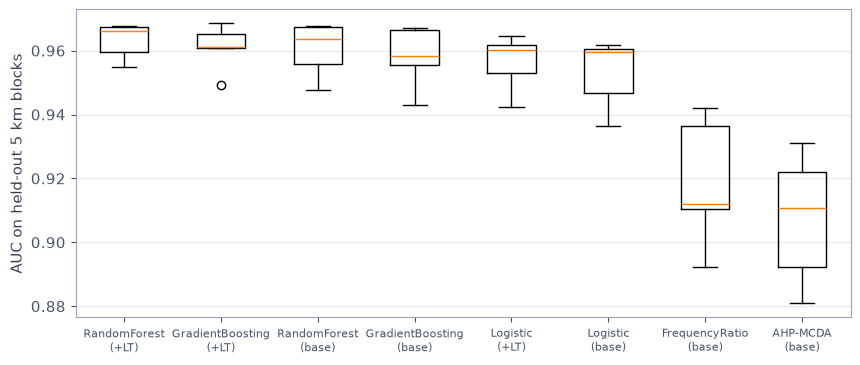

AUC gained by adding land type: {'Logistic': np.float64(0.003), 'RandomForest': np.float64(0.003), 'GradientBoosting': np.float64(0.003)}


In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
order = [(m, f) for m, f in perf.index]
ax.boxplot([cv[(cv.model == m) & (cv.features == f)].AUC for m, f in order])
ax.set_xticks(range(1, len(order) + 1), [f"{m}\n({f})" for m, f in order], fontsize=8)
ax.set_ylabel("AUC on held-out 5 km blocks")
ax.grid(axis="y", alpha=0.3)
plt.show()

gain = perf.loc[[(m, "+LT") for m in make_models()], ("AUC", "mean")].values - \
    perf.loc[[(m, "base") for m in make_models()], ("AUC", "mean")].values
print("AUC gained by adding land type:", dict(zip(make_models(), np.round(gain, 3))))

**Reading the cross-validation.** All models rank held-out flooded cells well above held-out dry ones. The tree ensembles lead, the logistic model follows, and the two transparent models (frequency ratio and AHP) are not far behind, which says the signal is mostly simple: low land floods. Adding land type helps only a little, because terrain already carries most of what it knows; the **base** models are used from here on, so no result depends on a predictor that encodes the target.

### Final models and susceptibility maps

Each model is refitted on all labelled cells and applied to every study cell.

Final fits and predictions in 3 s


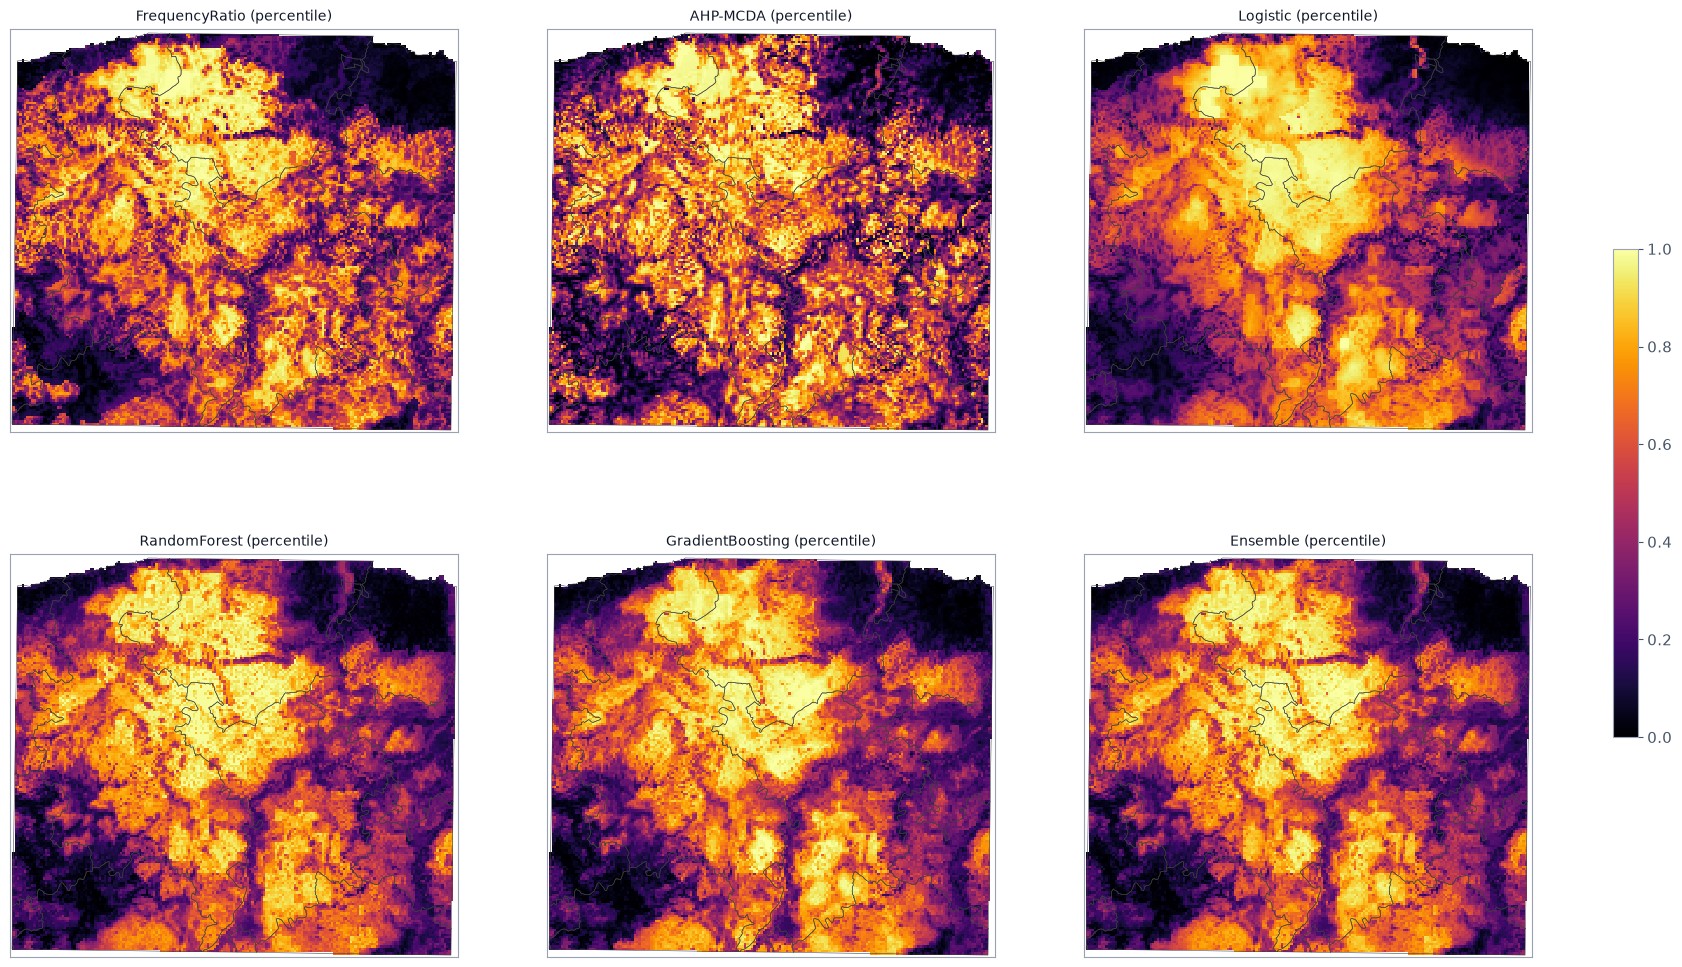

,FrequencyRatio,AHP-MCDA,Logistic,RandomForest,GradientBoosting,Ensemble
FrequencyRatio,1.00,0.93,0.89,0.90,0.88,0.89
AHP-MCDA,0.93,1.00,0.83,0.83,0.83,0.84
Logistic,0.89,0.83,1.00,0.95,0.95,0.96
RandomForest,0.90,0.83,0.95,1.00,0.98,0.99
GradientBoosting,0.88,0.83,0.95,0.98,1.00,0.99
Ensemble,0.89,0.84,0.96,0.99,0.99,1.00


In [21]:
t0 = time.time()
XA_all = X_SETS["base"].values.astype(np.float32)
FITTED = {}
for name, model in make_models().items():
    fit_kw = {f"{model.steps[-1][0]}__sample_weight" if name == "Logistic" else "sample_weight": weights}
    model.fit(XA_all[use], y, **fit_kw)
    FITTED[name] = model
    out = np.full(GRID.shape, np.nan)
    out[STUDY] = model.predict_proba(XA_all)[:, 1]
    SCORE[name] = out
print(f"Final fits and predictions in {time.time() - t0:.0f} s")


def pct_rank(arr):
    """Percentile rank (0 to 1) of every study cell, so that all models share one scale."""
    out = np.full(GRID.shape, np.nan)
    out[STUDY] = pd.Series(arr[STUDY]).rank(pct=True).values
    return out


PCT = {k: pct_rank(v) for k, v in SCORE.items()}
PCT["Ensemble"] = pct_rank((PCT["RandomForest"] + PCT["GradientBoosting"]) / 2)
MODELS = ["FrequencyRatio", "AHP-MCDA", "Logistic", "RandomForest", "GradientBoosting", "Ensemble"]

fig, axes = plt.subplots(2, 3, figsize=(21, 12.5))
for ax, m in zip(axes.ravel(), MODELS):
    im = show(ax, PCT[m], f"{m} (percentile)", "inferno", 0, 1)
plt.colorbar(im, ax=axes, fraction=0.015)
plt.show()

rank_corr = pd.DataFrame({m: PCT[m][STUDY] for m in MODELS}).corr(method="spearman")
display(rank_corr.round(2))

**Comparing the maps.** All six agree on the structure: the basin floor is highly susceptible, the piedmont, levees and southern terraces are not. They differ in texture. The frequency-ratio and AHP maps follow the DEM, and the AHP map is noisier because drainage class and TWI change from cell to cell. The machine-learning maps are smoother but carry square patches a few kilometres across in the south: they follow land-use code 3, whose cells (0.01°, about 1 km) are mostly flooded, so the trees learned it as a shortcut. A finer land-cover layer would remove them. The **ensemble** (mean rank of random forest and gradient boosting) is the headline map.

## What drives susceptibility?

**Permutation importance** measures how much the held-out AUC of the random forest falls when one predictor is shuffled; one-hot columns of a layer are shuffled together. **Partial dependence** shows the average modelled response to one predictor.

Held-out AUC of this fit: 0.967


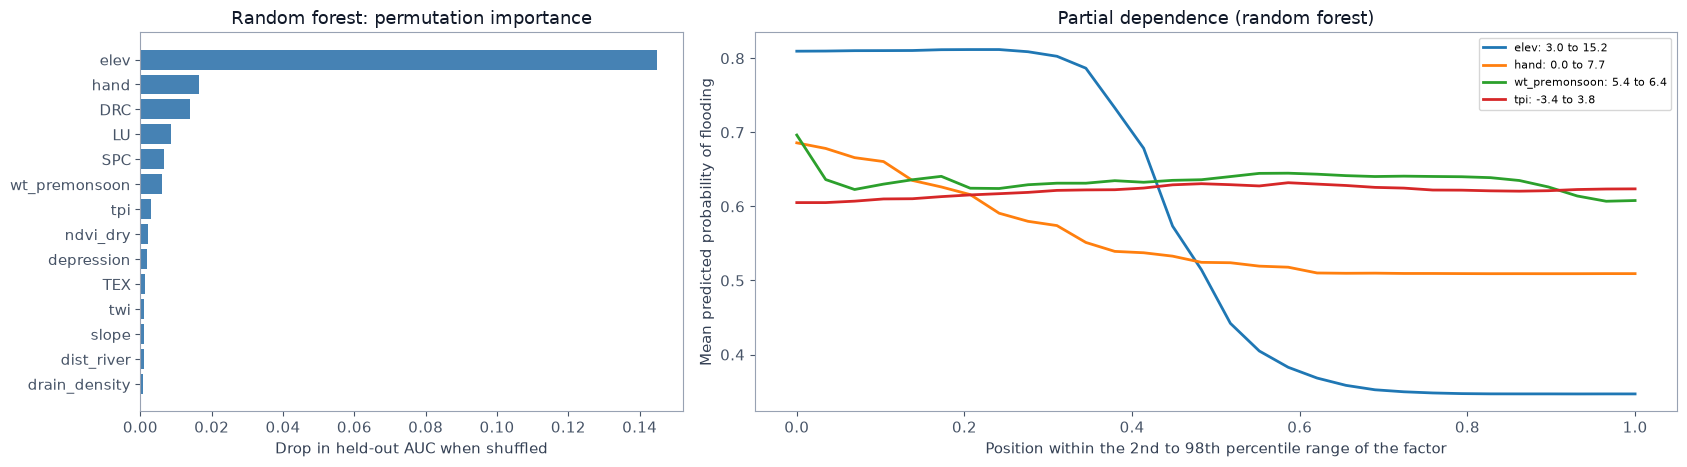

In [22]:
tr, te = FOLDS[0]
XA = XA_all[use]
rf_imp = make_models()["RandomForest"].fit(XA[tr], y[tr], sample_weight=weights[tr])
FEATS = X_SETS["base"].columns.tolist()
layer_of = {c: (c.split("_")[0] if c.split("_")[0] in CAT_ML else c) for c in FEATS}
base_auc = roc_auc_score(y[te], rf_imp.predict_proba(XA[te])[:, 1])
imp = {}
for layer in dict.fromkeys(layer_of.values()):
    cols = [FEATS.index(c) for c, l in layer_of.items() if l == layer]
    drops = []
    for rep in range(3):
        Xp = XA[te].copy()
        Xp[:, cols] = Xp[RNG.permutation(len(Xp))][:, cols]
        drops.append(base_auc - roc_auc_score(y[te], rf_imp.predict_proba(Xp)[:, 1]))
    imp[layer] = np.mean(drops)
imp = pd.Series(imp).sort_values(ascending=False)
print(f"Held-out AUC of this fit: {base_auc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})
axes[0].barh(imp.index[::-1], imp.values[::-1], color="steelblue")
axes[0].set_xlabel("Drop in held-out AUC when shuffled")
axes[0].set_title("Random forest: permutation importance")

rf = FITTED["RandomForest"]
sample = XA_all[RNG.choice(len(XA_all), 3000, replace=False)]
for name, col in zip([c for c in imp.index if c in NUM][:4], ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    j = FEATS.index(name)
    q = np.nanpercentile(XA_all[:, j], [2, 98])
    xs = np.linspace(*q, 30)
    resp = []
    for v in xs:
        Xs_ = sample.copy()
        Xs_[:, j] = v
        resp.append(rf.predict_proba(Xs_)[:, 1].mean())
    axes[1].plot((xs - q[0]) / (q[1] - q[0]), resp, color=col, lw=2, label=f"{name}: {q[0]:.1f} to {q[1]:.1f}")
axes[1].set_xlabel("Position within the 2nd to 98th percentile range of the factor")
axes[1].set_ylabel("Mean predicted probability of flooding")
axes[1].set_title("Partial dependence (random forest)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Elevation dominates by a wide margin, and its response is a threshold: the predicted probability is high below about 8 m and falls steeply over the next 2 to 3 m. HAND comes next, adding the local picture (a cell 2 m above the nearest drain floods less than one at the same absolute height beside it), followed by soil drainage class and land use. TWI, slope and the river-network factors add almost nothing once elevation is known.

## Validation of all models

### ROC curves and prediction-rate curves

Two complementary views of the out-of-fold predictions:

- **ROC curve and AUC**: how well each model separates flooded from dry cells over all thresholds.
- **Success and prediction rate curves**, standard in susceptibility mapping: rank all labelled cells from most to least susceptible and plot the cumulative share of flooded cells against the cumulative share of cells. The **success rate** uses the final model on the cells it was fitted to; the **prediction rate** uses out-of-fold predictions. A steeper curve is better, and a large gap between the two signals overfitting.

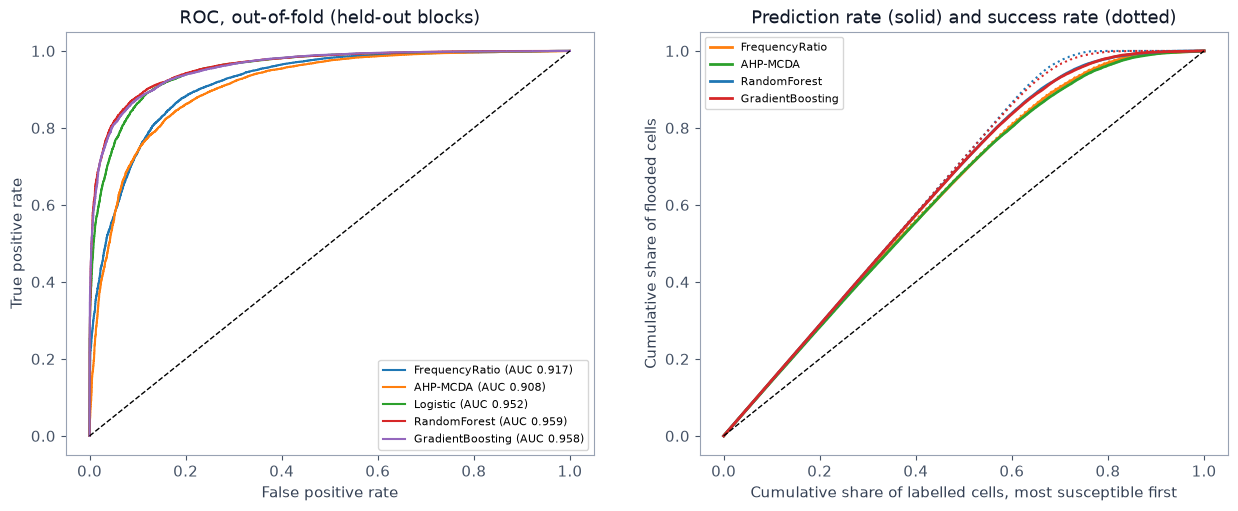

,success-rate AUC,prediction-rate AUC
model,,
FrequencyRatio,0.631,0.628
AHP-MCDA,0.626,0.626
RandomForest,0.652,0.641
GradientBoosting,0.650,0.641


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for m in MODELS[:-1]:
    p = OOF[(m, "base")]
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, label=f"{m} (AUC {roc_auc_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC, out-of-fold (held-out blocks)")
axes[0].legend(fontsize=8)


def rate_curve(score, yy):
    order = np.argsort(-score)
    return np.linspace(0, 1, len(yy)), np.cumsum(yy[order]) / yy.sum()


rows = []
for m, col in zip(["FrequencyRatio", "AHP-MCDA", "RandomForest", "GradientBoosting"],
                  ["tab:orange", "tab:green", "tab:blue", "tab:red"]):
    x, s = rate_curve(SCORE[m][STUDY][use], y)
    x, pr = rate_curve(OOF[(m, "base")], y)
    axes[1].plot(x, s, color=col, ls=":", lw=1.5)
    axes[1].plot(x, pr, color=col, lw=2, label=m)
    rows.append((m, np.trapezoid(s, x), np.trapezoid(pr, x)))
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("Cumulative share of labelled cells, most susceptible first")
axes[1].set_ylabel("Cumulative share of flooded cells")
axes[1].set_title("Prediction rate (solid) and success rate (dotted)")
axes[1].legend(fontsize=8)
plt.show()
display(pd.DataFrame(rows, columns=["model", "success-rate AUC", "prediction-rate AUC"]).set_index("model").round(3))

Because 69 % of the labelled cells are flooded, even a perfect model reaches all flooded cells only after 69 % of the cells, so the area under these curves cannot exceed about 0.65 (1 minus 0.69 / 2). Within that range the tree ensembles come closest, and the success and prediction curves of every model nearly coincide (the largest gap is about 0.01, for the random forest). The models therefore generalise to unseen blocks almost as well as they fit their training data.

### An independent check: the first radar date

The models were trained on water at the **peak**. Water on the **first** radar date, earlier in the event, was never used. If the maps describe susceptibility rather than one snapshot, they should also rank the cells flooded on the first date above the cells still dry.

In [24]:
y_pre = make_labels(PRE_FRAC)[STUDY]
ok_pre = np.isfinite(y_pre)
rows = []
for m in MODELS:
    rows.append((m, roc_auc_score(y_pre[ok_pre].astype(int), PCT[m][STUDY][ok_pre])))
display(pd.DataFrame(rows, columns=["model", "AUC on the first-date water map"]).set_index("model").round(3))
print(f"First date: {np.sum(y_pre == 1):,} flooded and {np.sum(y_pre == 0):,} dry labelled cells")

,AUC on the first-date water map
model,
FrequencyRatio,0.874
AHP-MCDA,0.866
Logistic,0.890
RandomForest,0.920
GradientBoosting,0.916
Ensemble,0.920


First date: 13,401 flooded and 12,832 dry labelled cells


All models keep high AUC against a water map they never saw. This test is not fully independent (the same basin, two weeks apart), but it shows that the ranking does not depend on the exact date of the training image.

## Susceptibility classes and model agreement

Each map is cut into **five equal-area classes** (quintiles of the study area): very low, low, moderate, high and very high. Equal-area classes make the models directly comparable, and the share of each class that actually flooded should rise steadily from very low to very high.

% of class area under water at the 2025 peak,very low,low,moderate,high,very high
FrequencyRatio,10.3,41.5,70.4,83.9,95.7
AHP-MCDA,12.6,42.2,69.3,85.0,92.8
Logistic,6.3,37.9,72.4,88.5,96.5
RandomForest,2.0,31.8,77.7,93.1,97.3
GradientBoosting,2.7,32.6,76.2,92.3,97.6
Ensemble,2.1,32.2,77.0,92.8,97.6


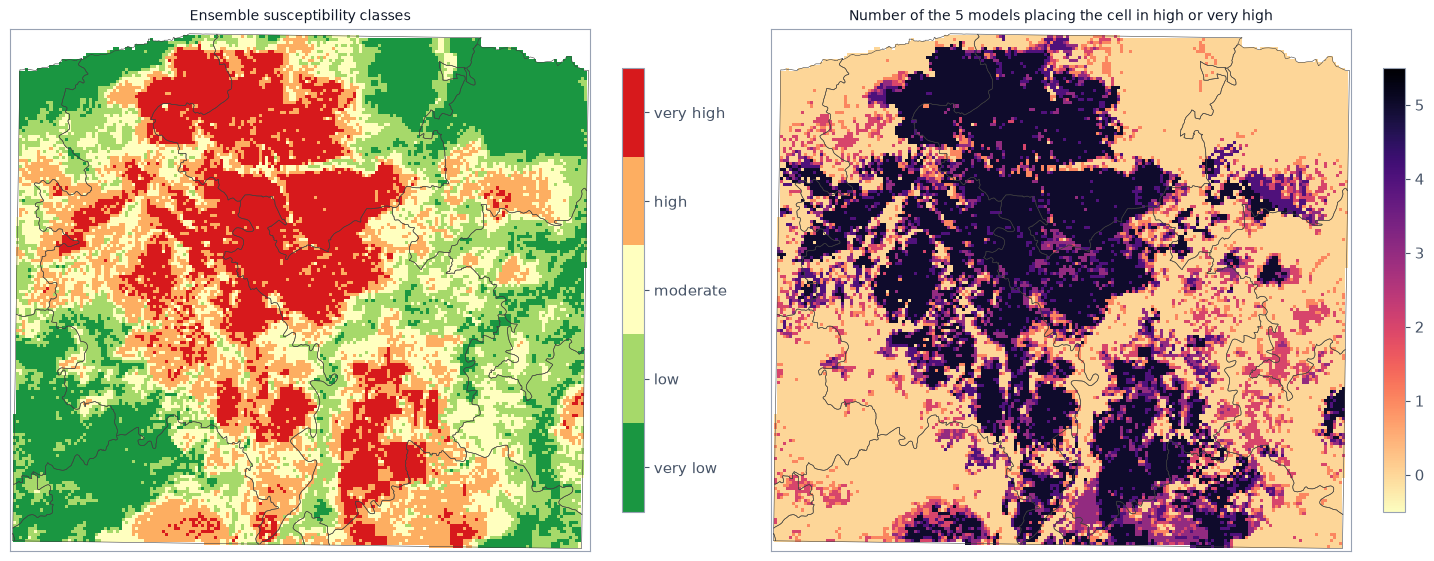

Cells that all five models place in high or very high: 27%; in none of them: 47%


In [25]:
CLASS_NAMES = ["very low", "low", "moderate", "high", "very high"]
CLASS_CMAP = ListedColormap(["#1a9641", "#a6d96a", "#ffffbf", "#fdae61", "#d7191c"])


def to_classes(pct):
    out = np.full(GRID.shape, np.nan)
    out[STUDY] = np.minimum((pct[STUDY] * 5).astype(int), 4)
    return out


CLS = {m: to_classes(PCT[m]) for m in MODELS}
rows = []
for m in MODELS:
    c = CLS[m][STUDY]
    ff = FLOOD_FRAC[STUDY]
    rows.append([np.nanmean(ff[c == k]) for k in range(5)])
cls_tab = pd.DataFrame(rows, index=MODELS, columns=CLASS_NAMES) * 100
display(cls_tab.round(1).rename_axis(columns="% of class area under water at the 2025 peak"))

agree = np.full(GRID.shape, np.nan)
agree[STUDY] = sum((CLS[m][STUDY] >= 3).astype(int) for m in MODELS[:-1])
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
im = show(axes[0], CLS["Ensemble"], "Ensemble susceptibility classes", CLASS_CMAP, -0.5, 4.5)
cb = plt.colorbar(im, ax=axes[0], fraction=0.035, ticks=range(5))
cb.ax.set_yticklabels(CLASS_NAMES)
im = show(axes[1], agree, "Number of the 5 models placing the cell in high or very high", "magma_r", -0.5, 5.5,
          )
plt.colorbar(im, ax=axes[1], fraction=0.035, ticks=range(6))
plt.show()
print(f"Cells that all five models place in high or very high: {np.mean(agree[STUDY] == 5):.0%}; "
      f"in none of them: {np.mean(agree[STUDY] == 0):.0%}")

For every model the flooded share rises steadily from the very-low class (2 % for the tree models, 10 to 13 % for frequency ratio and AHP) to the very-high class (93 to 98 %), the monotonic pattern a usable susceptibility map must show. The machine-learning models separate the two ends more sharply. The agreement map is a practical product in its own right: about a quarter of the basin is high or very high in all five models and nearly half in none, so the class is robust to the choice of method over most of the area. Disagreement is concentrated on the transition belts between the basin floor and the higher land, where 250 m cells mix both.

## Uncertainty

Three sources of uncertainty are examined:

- **AHP weights.** `monte_carlo_weights` draws 500 weight vectors from a Dirichlet distribution around the AHP weights and reports how often each cell stays in the top 40 % (the high and very-high classes).
- **Label thresholds.** The flooded label needs at least 50 % open water. The random forest is cross-validated again with 30 % and 70 %, and the very-high classes are compared with `jaccard_index`.
- **Method.** The Jaccard overlap of the very-high classes of each pair of models.

Monte Carlo weights in 1.1 s; median Jaccard of top-40 % sets vs AHP baseline 0.96


,labelled cells,share flooded,spatial-CV AUC,Jaccard of very-high class vs 50 % run
flooded label,,,,
>= 30% water,28747,0.711,0.948,0.853
>= 50% water,26994,0.693,0.960,0.908
>= 70% water,25158,0.670,0.968,0.849


Jaccard of very-high classes,FrequencyRatio,AHP-MCDA,Logistic,RandomForest,GradientBoosting
FrequencyRatio,1.00,0.56,0.61,0.61,0.60
AHP-MCDA,0.56,1.00,0.41,0.41,0.46
Logistic,0.61,0.41,1.00,0.72,0.69
RandomForest,0.61,0.41,0.72,1.00,0.70
GradientBoosting,0.60,0.46,0.69,0.70,1.00


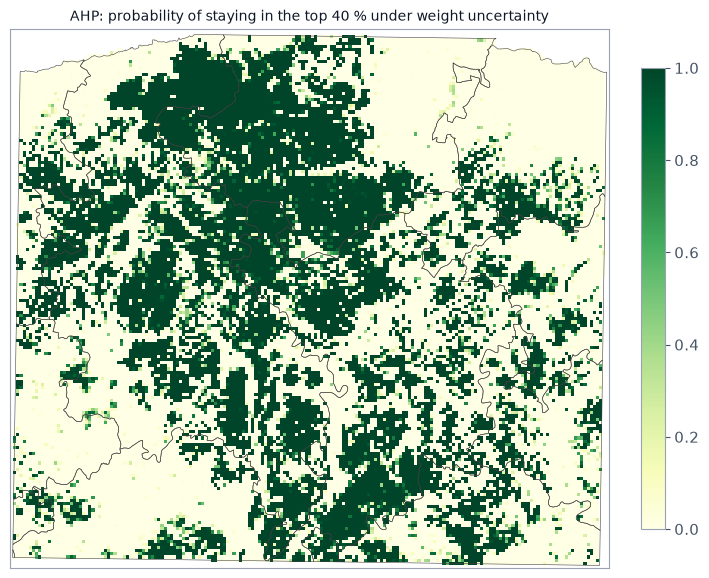

In [26]:
M = np.stack([MEMBERS[k][STUDY] for k in CRITERIA])
t0 = time.time()
mc = monte_carlo_weights(M, W_AHP.values, kappa=50.0, n=500, batch=50, top_q=0.6, seed=11)
p_top = np.full(GRID.shape, np.nan)
p_top[STUDY] = mc["p_top"]
print(f"Monte Carlo weights in {time.time() - t0:.1f} s; median Jaccard of top-40 % sets vs AHP baseline "
      f"{np.median(mc['jaccard']):.2f}")

rows = []
top_ref = CLS["RandomForest"][STUDY] == 4
for fmin in (0.3, 0.5, 0.7):
    lab_t = make_labels(FLOOD_FRAC, flood_min=fmin)[STUDY]
    u = np.isfinite(lab_t)
    yt = lab_t[u].astype(int)
    wt_ = np.where(yt == 1, 0.5 / yt.mean(), 0.5 / (1 - yt.mean()))
    gt = blocks[u]
    aucs = []
    for tr, te in GroupKFold(n_splits=N_FOLDS).split(np.zeros(len(yt)), yt, gt):
        mdl = make_models()["RandomForest"].set_params(n_estimators=150)
        p = mdl.fit(XA_all[u][tr], yt[tr], sample_weight=wt_[tr]).predict_proba(XA_all[u][te])[:, 1]
        aucs.append(roc_auc_score(yt[te], p))
    mdl = make_models()["RandomForest"].set_params(n_estimators=150).fit(XA_all[u], yt, sample_weight=wt_)
    pr = mdl.predict_proba(XA_all)[:, 1]
    top = pr >= np.quantile(pr, 0.8)
    rows.append((f">= {fmin:.0%} water", u.sum(), yt.mean(), np.mean(aucs), jaccard_index(top, top_ref)))
display(pd.DataFrame(rows, columns=["flooded label", "labelled cells", "share flooded", "spatial-CV AUC",
                                    "Jaccard of very-high class vs 50 % run"]).set_index("flooded label").round(3))

jac = pd.DataFrame(index=MODELS[:-1], columns=MODELS[:-1], dtype=float)
for a in MODELS[:-1]:
    for b in MODELS[:-1]:
        jac.loc[a, b] = jaccard_index(CLS[a][STUDY] == 4, CLS[b][STUDY] == 4)
display(jac.round(2).rename_axis(columns="Jaccard of very-high classes"))

fig, ax = plt.subplots(figsize=(8.5, 7))
im = show(ax, p_top, "AHP: probability of staying in the top 40 % under weight uncertainty", "YlGn", 0, 1)
plt.colorbar(im, ax=ax, fraction=0.035)
plt.show()

**Reading the uncertainty.** The AHP ranking is stable to the weights: the top-40 % set of a typical random weight vector shares about 95 % of its cells with the baseline, and only the edges of the basin floor switch class. The random forest is insensitive to where the flooded label is cut (spatial-CV AUC 0.95 to 0.97, Jaccard of the very-high class about 0.85 against the 50 % run). The choice of method matters more: the very-high classes of two models share between 40 % and 72 % of their cells, lowest between AHP and the machine-learning models. That is why the agreement map of Section 13 is reported alongside the ensemble.

## Exposure

The population grid gives persons per 1 km cell for 2020. It is averaged onto the 250 m grid and scaled by the cell area (0.0625 km²), so that the sum over the AOI is preserved. Exposure is reported for the ensemble map by susceptibility class and, for the high and very-high classes, by **upazila**.

Population in the study area (2020): 1,377,501


,area_km2,population,flooded_2025_pct,population_pct
very low,385.3,497672.5,2.1,36.1
low,385.3,386361.3,32.2,28.0
moderate,385.3,252183.1,77.0,18.3
high,385.3,157816.4,92.8,11.5
very high,385.4,83467.6,97.6,6.1


,upazila,district,area_km2,high_vhigh_area_pct,population,pop_high_vhigh,pop_high_vhigh_pct
0,Dharampasha,Sunamganj,501.0,56.1,270570.7,85671.0,31.7
1,Tahirpur,Sunamganj,300.2,58.1,225458.4,59581.1,26.4
2,Jamalganj,Sunamganj,326.6,53.1,181646.6,42151.8,23.2
3,Derai,Sunamganj,114.8,47.5,74463.0,23301.5,31.3
4,Bishwambarpur,Sunamganj,175.9,16.0,169912.2,15839.1,9.3
5,Mohanganj,Netrakona,148.6,20.2,133403.1,7749.1,5.8
6,Kalmakanda,Netrakona,72.7,21.0,30863.4,2675.0,8.7
7,Sunamganj Sadar,Sunamganj,101.2,5.3,109356.7,1951.7,1.8
8,Dakshin Sunamganj,Sunamganj,93.8,6.3,68651.0,1791.8,2.6
9,Barhatta,Netrakona,75.0,1.6,102848.3,442.7,0.4


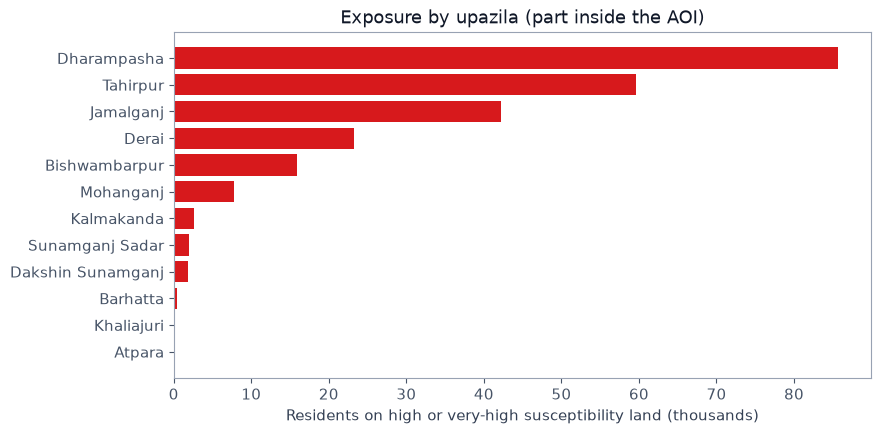

In [27]:
pop_gt = gdal.Open(str(BD / "population_2020.tif")).GetGeoTransform()
cell_ratio = GRID.res ** 2 / abs(pop_gt[1] * pop_gt[5])  # 250 m cell area / native cell area
pop = dp.warp_to_grid(BD / "population_2020.tif", GRID, resample="average") * cell_ratio
pop = np.where(STUDY & np.isfinite(pop), pop, 0)
ens = CLS["Ensemble"]
by_class = pd.DataFrame({
    "area_km2": [np.sum(ens == k) * 0.0625 for k in range(5)],
    "population": [pop[ens == k].sum() for k in range(5)],
    "flooded_2025_pct": cls_tab.loc["Ensemble"].values,
}, index=CLASS_NAMES)
by_class["population_pct"] = by_class.population / by_class.population.sum() * 100
print(f"Population in the study area (2020): {pop.sum():,.0f}")
display(by_class.round(1))

upz_id = np.zeros(GRID.shape, int)
for i, g in enumerate(upz.geometry, start=1):
    upz_id[dp.rasterize_geometries([g], GRID, all_touched=False).astype(bool)] = i
rows = []
for i, r in enumerate(upz.itertuples(), start=1):
    m = (upz_id == i) & STUDY
    hi = m & (ens >= 3)
    rows.append((r.ADM3_EN, r.ADM2_EN, m.sum() * 0.0625, hi.sum() / max(m.sum(), 1) * 100, pop[m].sum(),
                 pop[hi].sum(), pop[hi].sum() / max(pop[m].sum(), 1) * 100))
exposure = pd.DataFrame(rows, columns=["upazila", "district", "area_km2", "high_vhigh_area_pct", "population",
                                       "pop_high_vhigh", "pop_high_vhigh_pct"])
exposure = exposure[exposure.area_km2 >= 5].sort_values("pop_high_vhigh", ascending=False).reset_index(drop=True)
display(exposure.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(exposure.upazila[::-1], exposure.pop_high_vhigh[::-1] / 1000, color="#d7191c")
ax.set_xlabel("Residents on high or very-high susceptibility land (thousands)")
ax.set_title("Exposure by upazila (part inside the AOI)")
plt.show()

Two findings stand out. First, people live disproportionately on the **less** susceptible land: each class covers a fifth of the area, but the very-low class holds about 36 % of the residents and the very-high class about 6 %. Villages in the haors sit on levees, piedmont and raised platforms. Second, the absolute numbers on high and very-high land are still large in the upazilas whose territory is mostly haor (Dharampasha, Tahirpur and Jamalganj, where more than half of the area is high or very high). That is where embankment maintenance, flood shelters and early-harvest support for boro farmers pay off most. Population at 1 km is spread evenly within each 1 km cell when it is moved to 250 m, so the split between a raised village and its surrounding fields inside one 1 km cell is not resolved.

## Outputs

All rasters are GeoTIFFs on the 250 m UTM 46N analysis grid in `Data/03_spatial_analysis/capstone_spatial_analysis/sylhet_flood/`.

In [28]:
def save(name, arr, dtype="float32"):
    return GRID.write(OUT / name, np.where(STUDY, arr, np.nan), dtype=dtype)


save("flood_fraction_peak_250m.tif", FLOOD_FRAC)
save("flood_labels_250m.tif", LABEL)
for m in MODELS:
    save(f"susceptibility_pct_{m}_250m.tif", PCT[m])
    save(f"class_{m}_250m.tif", CLS[m])
save("model_agreement_250m.tif", agree)
save("ahp_p_top40_250m.tif", p_top)
pd.DataFrame({k: FACT[k][STUDY] for k in NUM}).assign(label=LABEL[STUDY], row=rows_, col=cols_) \
    .to_csv(OUT / "factor_table.csv.gz", index=False)
W_AHP.rename("weight").to_csv(OUT / "ahp_weights.csv")
perf.round(4).to_csv(OUT / "cross_validation.csv")
by_class.to_csv(OUT / "exposure_by_class.csv")
upz.merge(exposure, left_on="ADM3_EN", right_on="upazila").to_file(OUT / "exposure_by_upazila.gpkg", driver="GPKG")
for p in sorted(OUT.glob("*.*")):
    print(f"{p.name:45s} {p.stat().st_size / 1024:8.0f} KB")

ahp_p_top40_250m.tif                               129 KB
ahp_weights.csv                                      0 KB
class_AHP-MCDA_250m.tif                            129 KB
class_Ensemble_250m.tif                            129 KB
class_FrequencyRatio_250m.tif                      129 KB
class_GradientBoosting_250m.tif                    129 KB
class_Logistic_250m.tif                            129 KB
class_RandomForest_250m.tif                        129 KB
cross_validation.csv                                 0 KB
exposure_by_class.csv                                0 KB
exposure_by_upazila.gpkg                           700 KB
factor_table.csv.gz                               2152 KB
flood_fraction_peak_250m.tif                       129 KB
flood_labels_250m.tif                              129 KB
model_agreement_250m.tif                           129 KB
susceptibility_pct_AHP-MCDA_250m.tif               129 KB
susceptibility_pct_Ensemble_250m.tif               129 KB
susceptibility

## Limitations

- **A 250 m DEM in a flat basin.** Relief across the AOI is about 15 m. Village platforms, embankments and channels are narrower than one cell, so the maps describe neighbourhoods, not individual plots. Because elevation dominates, errors in the national DEM pass straight into every model.
- **One season of labels.** The inventory is one flood peak in one year. A large but different event, such as an April flash flood before the boro harvest, can flood land in a different order. Several years of radar would turn the single map into a flood frequency.
- **What radar misses.** Water under dense vegetation and in built-up areas can look like land in VH backscatter, and wind-roughened water can look like land too. The Otsu threshold is a single global value.
- **Mixed seasons of the factors.** NDVI and water table are from 2020, land use from 2020, soils from the national survey; they describe typical conditions, not 2025.
- **Forcing outside the AOI.** The cause of the floods, rain on the Meghalaya plateau and the flow of the Surma and Kushiyara from India, lies outside the window. A susceptibility map cannot represent it; a hydrodynamic model can.
- **Legends.** The land-use and texture rasters have no legend in the folder, so they are used as unnamed categories; the meaning of the SDC depth classes should be confirmed before it is used.

## Where to go next

- Rebuild the inventory from **all four Sentinel-1 dates** (24 May, 5 June, 11 July, 16 August) and model the number of dates under water, not a single map. The raw scenes are in `Sylhet_sentinel1/`.
- Replace the 250 m DEM with **Copernicus GLO-30 or FABDEM** at 30 m and compare the maps, as the landslide capstone does for its covariate grid.
- Add **embankments** and **roads** from OpenStreetMap: in the haors they decide which beds fill first.
- Compare the susceptibility classes with a **HEC-RAS or LISFLOOD-FP** inundation model driven by the 2025 rainfall.
- Use the upazila exposure table with the **network analysis** of Module 03.05 to locate flood shelters within reach of the most exposed villages.